# **AI METHODS I**
## Day I: Data cleaning and Exploratory Data Analysis (EDA)

Welcome! This is the first notebook of **AI Methods I: Machine Learning for the Built Environment**.

Before we can train any machine learning model, we need data that is **clean**, **well understood** and **in the right format**. In real projects this step often takes *most* of the time (people like to say 80%). A model is only as good as the data we feed it: *garbage in, garbage out*.

### Learning goals
By the end of this notebook you will be able to:
1. Load a dataset from Kaggle directly into **pandas**.
2. Inspect a dataset and write a short **dataset card** (source, content, limitations).
3. Detect and fix the classic data problems: **duplicates**, **missing values**, **inconsistent data types** and **outliers**.
4. **Engineer new features** from messy text columns (e.g. number of bedrooms from a title).
5. Explore the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).
6. Save a clean, **model-ready dataset** for Day 2 (supervised learning).

### The data science workflow
```
 ┌───────────┐   ┌───────────┐   ┌───────────┐   ┌───────────┐   ┌──────────────┐
 │  ACQUIRE  │ → │   CLEAN   │ → │  EXPLORE  │ → │   MODEL   │ → │ COMMUNICATE  │
 │ get data  │   │ fix it    │   │ (EDA)     │   │ (ML)      │   │ plots, repo, │
 │           │   │           │   │ understand│   │           │   │ blog post    │
 └───────────┘   └───────────┘   └───────────┘   └───────────┘   └──────────────┘
 \_______________ today (Day 1) _______________/   Day 2 & 3      every day!
```
The arrows are not one-way: what you discover while exploring often sends you back to cleaning.

### Why house prices, in an architecture course?
Real-estate listings are one of the largest openly available datasets about **buildings**. Every listing describes a dwelling through variables that architects design every day: **floor area**, **number of rooms (typology)**, **floor level**, **orientation**, **views**, **balconies**, **parking**… and attaches a **price** to it. This lets us ask design questions with data:
- How much is an extra square metre worth in different cities?
- Do people pay more for an east-facing flat, or for a view of a park?
- Is there a premium for living on higher floors?

### Table of contents
0. Setup and data acquisition
1. Data cleaning
2. Exploratory Data Analysis (EDA)
3. Conclusions and next steps

> **How to use this notebook:** run the cells **from top to bottom** (`Shift + Enter`). Read the markdown before each code cell: it explains *what* we do and *why*. Cells marked **Your turn** are short exercises for you.

# 0. Setup and data acquisition

## 0.1 Here we will import the general libraries we will use in this notebook.

| Library | What we use it for |
|---|---|
| `pandas` (`pd`) | Tables (**DataFrames**): loading, filtering, cleaning, grouping |
| `numpy` (`np`) | Fast maths on arrays, and `np.nan` (the "missing value" marker) |
| `matplotlib.pyplot` (`plt`) | The base plotting library: figures, axes, titles, saving images |
| `seaborn` (`sns`) | Statistical plots on top of matplotlib, with nicer defaults and less code |
| `kagglehub` (`kh`) | Downloading datasets directly from [Kaggle](https://www.kaggle.com) |
| `pathlib.Path` | Building file paths that work on Windows, macOS, Linux and Colab |
| `scikit-learn` | The machine learning library of the course. Today only for **imputation** (section 1.10); we import it there |

💡 **Tip – Google Colab:** if you run this notebook in Colab (or a fresh environment), uncomment and run the next cell first to install the libraries.

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

Next we set up a few **settings** that we will use through the whole notebook:
- **Folders** for data and figures. We use *relative* paths (relative to where this notebook is), so the notebook works on any computer. ⚠️ Never write paths like `/home/my_name/...` in a notebook you share: they only exist on *your* machine.
- **Display options** so pandas shows all columns and readable numbers.
- A **plot style** for seaborn and a default figure size.
- A small helper function `save_fig()` to export the important plots as `.png` (you will need these for your deliverables and blog post).

In [3]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## 0.2 Where does built-environment data come from?

Before loading anything, it is worth knowing the typical **sources of data** in architecture, engineering and construction (AEC):

| Source | Examples | Typical format |
|---|---|---|
| **Open data portals** | City cadastre, building permits, census, energy certificates (e.g. Open Data BCN, Eurostat) | CSV, GeoJSON, API |
| **BIM / design models** | Element schedules exported from Revit, ArchiCAD, Grasshopper | IFC, CSV, JSON |
| **Sensors / IoT** | Temperature, CO₂, energy meters, site monitoring | Time series (CSV, databases) |
| **Images and scans** | Façade photos, drone imagery, point clouds | JPG, PNG, LAS/PLY |
| **Web / scraped data** | Real-estate listings, reviews, maps | HTML → CSV |
| **Data platforms** | Kaggle, Hugging Face, Zenodo | CSV, Parquet, … |

Today's dataset is **web-scraped real-estate listings** published on **Kaggle**. Each source comes with its own typical problems. Scraped data, for example, is famous for duplicates, text where we expect numbers, and inconsistent units. We will meet all of them today.

## 0.3 Using kaggle to load the dataset directly from their website

We use `kagglehub.dataset_download()`, which downloads the file (only the first time, then it uses a local cache) and gives us its **path** on our computer. Then pandas reads it into a **DataFrame**. It needs two things:

1. **The dataset handle**: `"owner/dataset-name"`, taken from the dataset URL: kaggle.com/datasets/**juhibhojani/house-price**.
2. **The file name inside the dataset**: `"house_prices.csv"`. You can see it in the *Data* tab of the Kaggle page.

⚠️ **Watch out:** the file name is the name of the file **on Kaggle**, not a path on your computer. Passing a local path gives a `400 Bad Request` error.

⚠️ **Watch out:** Kaggle sends big files **zipped**. On Windows, `kagglehub` sometimes forgets to unzip it and saves the zip under the name `house_prices.csv`. Reading it as a normal CSV then fails with `'utf-8' codec can't decode byte 0x86`. That is why we check with `zipfile.is_zipfile()` and let pandas unzip it when needed.

💡 **Tip:** this dataset is public, so no Kaggle API key is needed. For private datasets or competitions you need to log in first with `kh.login()` (never paste your API key into a notebook you push to GitHub!).

In [4]:
# Download (or reuse from the cache) the CSV file and get its path on our computer
csv_path = kh.dataset_download(
    "juhibhojani/house-price",     # dataset handle: owner/dataset-name
    path="house_prices.csv",       # file name inside the Kaggle dataset
)

# If Kaggle sent the file zipped (and it was not unzipped), pandas unzips it while reading
is_zip = zipfile.is_zipfile(csv_path)
df = pd.read_csv(csv_path, compression="zip" if is_zip else None)

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 187,531 rows and 21 columns


We also keep a **copy of the raw data** in our `data/` folder. Good practice: **never modify the raw data**. All cleaning happens in code, so anyone can re-run the notebook and get the same result (*reproducibility*).

⚠️ **Watch out:** this raw file is ~106 MB, which is bigger than GitHub's 100 MB file limit. That is why it is listed in the repository's `.gitignore`: it stays on your computer and is never pushed. The *clean* file we produce at the end is much smaller.

In [5]:
raw_path = DATA_DIR / "house_prices_raw.csv"

# Writing 100+ MB takes a few seconds, so we only do it the first time
if not raw_path.exists():
    df.to_csv(raw_path, index=False)  # index=False: do not write pandas' row numbers as an extra column
    print(f"Raw data saved to {raw_path}")
else:
    print(f"Raw data already saved in {raw_path}")

Raw data already saved in data/house_prices_raw.csv


## 0.4 Dataset card

Every deliverable in this course needs a short description of the **use case** and the **source of the dataset**. A *dataset card* is a compact way to do it. Here is the one for today's data:

| | |
|---|---|
| **Name** | House Price (India) |
| **Source** | Kaggle, [juhibhojani/house-price](https://www.kaggle.com/datasets/juhibhojani/house-price) |
| **Origin** | Listings scraped from an Indian real-estate portal |
| **Unit of observation** | One row = one **listing** of a flat for sale |
| **Size (raw)** | 187,531 rows × 21 columns |
| **Target for Day 2** | `amount`: the asking price of the flat |
| **Licence** | Check the *License* field on the Kaggle page before re-using the data in a publication |
| **Known limitations** | Asking prices (not final sale prices), only Indian cities, many duplicates and missing values, prices in Indian units (*Lakh*, *Crore*) |

🤔 **Think about it:** an *asking* price is what the seller hopes to get, not what the buyer actually paid. How could that affect any conclusion we draw from this data?

## 0.5 First look at the data

The first thing to do with any new dataset is simply to **look at it**. Four commands give us most of the picture:

| Command | What it tells us |
|---|---|
| `df.shape` | Number of rows and columns |
| `df.head()` | The first rows: what the values look like |
| `df.info()` | Column names, data types and how many values are *not* missing |
| `df.describe()` | Summary statistics (mean, min, max, quartiles…) |

In [6]:
# The first 5 rows. Look carefully at the values: are the numbers really numbers?
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,"6,000.00",thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,"13,799.00",thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,"17,500.00",thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,"18,824.00",thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [7]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  str    
 2   Description        184508 non-null  str    
 3   Amount(in rupees)  187531 non-null  str    
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  str    
 6   Carpet Area        106858 non-null  str    
 7   Status             186916 non-null  str    
 8   Floor              180454 non-null  str    
 9   Transaction        187448 non-null  str    
 10  Furnishing         184634 non-null  str    
 11  facing             117298 non-null  str    
 12  overlooking        106095 non-null  str    
 13  Society            77853 non-null   str    
 14  Bathroom           186703 non-null  str    
 15  Balcony            138596 non-null  str    
 16  Car Parking  

**What do we notice already?**
- Only **3 columns are numeric** (`int64` / `float64`): `Index`, `Price (in rupees)` and two completely empty columns. Everything else is stored as **text** (`str`), even things that should be numbers, like `Bathroom`, `Carpet Area` or `Amount(in rupees)`.
- The **Non-Null Count** varies a lot between columns: we have **missing values**.
- `Dimensions` and `Plot Area` have **0 non-null values**: they are completely empty.

`describe()` confirms it. By default it only summarises numeric columns; with `include="all"` it also describes text columns (`unique` = number of different values, `top` = most frequent value, `freq` = how often it appears).

In [8]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Index,"187,531.00",NaN,NaN,NaN,"93,765.00","54,135.68",0.00,"46,882.50","93,765.00","140,647.50","187,530.00"
Title,187531,32446,2 BHK Ready to Occupy Flat for sale in Divyasr...,2106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,184508,65634,Multistorey apartment is available for sale. I...,2732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amount(in rupees),187531,1561,Call for Price,9684,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price (in rupees),"169,866.00",NaN,NaN,NaN,"7,583.77","27,241.71",0.00,"4,297.00","6,034.00","9,450.00","6,700,000.00"
location,187531,81,new-delhi,27599,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Carpet Area,106858,2758,1000 sqft,5285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,186916,1,Ready to Move,186916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Floor,180454,947,2 out of 4,12433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction,187448,4,Resale,144172,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data dictionary

Here is what each column means, and how an architect might read it:

| Column | Meaning | Architectural reading | Problem spotted |
|---|---|---|---|
| `Index` | Row number from the scraper | – | Not real information |
| `Title` | Listing title, e.g. *"2 BHK Ready to Occupy Flat for sale in…"* | **Typology**: BHK = Bedroom, Hall, Kitchen. A "2 BHK" is a 2-bedroom flat | Number hidden inside text |
| `Description` | Free text written by the seller | – | Long free text |
| `Amount(in rupees)` | Asking price, e.g. *"42 Lac"*, *"1.40 Cr"* | Value of the dwelling | Text with Indian units: 1 Lakh = 100,000 ₹, 1 Crore = 10,000,000 ₹ |
| `Price (in rupees)` | Another price column | ? (we will find out) | Ambiguous name |
| `location` | City | Urban context | Lowercase with hyphens |
| `Carpet Area` | Usable floor area inside the walls | **Net** area | Text with mixed units (sqft, sqyrd, sqm…) |
| `Super Area` | Carpet area + walls + share of common areas | **Gross** area | Text with mixed units, many missing |
| `Status` | Construction status | – | One single value? |
| `Floor` | e.g. *"10 out of 11"* | **Floor level** and **building height** | Two numbers inside one text |
| `Transaction` | New property or resale | Age / market | A few odd categories |
| `Furnishing` | Furnished, semi-furnished, unfurnished | Interior fit-out | – |
| `facing` | Direction the main façade faces | **Orientation** | Many missing |
| `overlooking` | e.g. *"Garden/Park, Main Road"* | **Views** | Several values in one cell |
| `Society` | Name of the residential complex | – | Thousands of different names |
| `Bathroom`, `Balcony` | Counts | Program / amenities | Numbers stored as text, e.g. *"> 10"* |
| `Car Parking` | e.g. *"1 Covered"* | Parking provision | Inconsistent text |
| `Ownership` | Freehold, leasehold… | Legal tenure | – |
| `Dimensions`, `Plot Area` | Plot information | – | 100% empty |

We now have a list of problems to fix. Let's clean!

# 1. Data cleaning

**Golden rule:** we never overwrite the original `df`. We work on a **copy** called `df_clean`, so we can always compare *before vs after* and go back if we make a mistake.

We follow this order:
1. Tidy column names
2. Remove duplicates
3. Get an overview of missing values
4. Drop useless columns
5. Fix data types (text → numbers)
6. Engineer new features
7. Clean the categorical columns
8. Understand the price columns
9. Handle outliers
10. Handle the remaining missing values
11. Final check and save

In [9]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

## 1.1 Tidy column names

Names like `Amount(in rupees)` or `Car Parking` (with spaces, brackets and capitals) are annoying to type and easy to misspell. A common convention is **snake_case**: lowercase words joined by underscores.

We rename with a **dictionary** `{old_name: new_name}`. For now we call the mysterious `Price (in rupees)` column just `price`; we will find out what it really is in section 1.8.

In [10]:
new_names = {
    "Index": "index",
    "Title": "title",
    "Description": "description",
    "Amount(in rupees)": "amount",
    "Price (in rupees)": "price",
    "location": "location",
    "Carpet Area": "carpet_area",
    "Status": "status",
    "Floor": "floor",
    "Transaction": "transaction",
    "Furnishing": "furnishing",
    "facing": "facing",
    "overlooking": "overlooking",
    "Society": "society",
    "Bathroom": "bathroom",
    "Balcony": "balcony",
    "Car Parking": "car_parking",
    "Ownership": "ownership",
    "Super Area": "super_area",
    "Dimensions": "dimensions",
    "Plot Area": "plot_area",
}

df_clean = df_clean.rename(columns=new_names)
df_clean.columns.tolist()

['index',
 'title',
 'description',
 'amount',
 'price',
 'location',
 'carpet_area',
 'status',
 'floor',
 'transaction',
 'furnishing',
 'facing',
 'overlooking',
 'society',
 'bathroom',
 'balcony',
 'car_parking',
 'ownership',
 'super_area',
 'dimensions',
 'plot_area']

## 1.2 Duplicates

A **duplicate** is a row that appears more than once. Duplicates are dangerous: they make some listings count double in every average and plot, and later they can make a model look better than it really is (the same flat ends up in both the training and the test set).

Let's ask pandas how many duplicated rows there are:

In [11]:
# .duplicated() returns True for every row that is an exact copy of an earlier row
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 0


Zero duplicates… but is that true? The `index` column is just a **row counter** added by the scraper, so it is *different in every row*, even when everything else is identical. It hides the duplicates! Let's check again **ignoring** the `index` column:

In [12]:
# Is the index column unique? (every value different)
print(f"Is 'index' unique? {df_clean['index'].is_unique}")

# Look for duplicates in all the other columns
n_duplicates = df_clean.drop(columns="index").duplicated().sum()
share = n_duplicates / len(df_clean)
print(f"Duplicated rows when ignoring 'index': {n_duplicates:,} ({share:.0%} of the dataset!)")

Is 'index' unique? True
Duplicated rows when ignoring 'index': 119,339 (64% of the dataset!)


In [13]:
# Let's see an example: one listing title that appears several times
# keep=False marks ALL copies as duplicates (not only the 2nd, 3rd...), so we can see them together
is_dup = df_clean.drop(columns="index").duplicated(keep=False)
example_title = df_clean.loc[is_dup, "title"].iloc[0]

df_clean[df_clean["title"] == example_title].head(4)

,index,title,description,amount,price,location,carpet_area,status,floor,transaction,furnishing,facing,overlooking,society,bathroom,balcony,car_parking,ownership,super_area,dimensions,plot_area
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
713,713,1 BHK Ready to Occupy Flat for sale Kasheli,This exquisite 1 BHK Flat is offered for sale ...,25 Lac,"4,274.00",thane,NaN,Ready to Move,1 out of 3,Resale,Semi-Furnished,NaN,NaN,NaN,1,1,NaN,NaN,585 sqft,NaN,NaN
146572,146572,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
147275,147275,1 BHK Ready to Occupy Flat for sale Kasheli,This exquisite 1 BHK Flat is offered for sale ...,25 Lac,"4,274.00",thane,NaN,Ready to Move,1 out of 3,Resale,Semi-Furnished,NaN,NaN,NaN,1,1,NaN,NaN,585 sqft,NaN,NaN


The rows are identical except for `index`. So we:
1. **Drop** the `index` column (it carries no information).
2. **Remove the duplicates** with `drop_duplicates()`, which keeps the first copy of each row.
3. **Reset the row numbers** with `reset_index(drop=True)` so they go 0, 1, 2… again.

In [14]:
rows_before = len(df_clean)

df_clean = df_clean.drop(columns="index")
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f"Rows before: {rows_before:,}")
print(f"Rows after:  {len(df_clean):,}")
print(f"Removed:     {rows_before - len(df_clean):,} duplicated rows")

Rows before: 187,531
Rows after:  68,192
Removed:     119,339 duplicated rows


🤔 **Think about it:** almost two thirds of the dataset were copies! Why would a scraped dataset contain so many duplicates? (Hint: think about how a scraper browses a website page by page, and about sellers who post the same flat several times.) What would have happened to our averages if we had not noticed?

## 1.3 Missing values overview

In pandas, missing values appear as `NaN` (*Not a Number*). `.isna()` returns `True` where a value is missing; summing it counts the missing values per column.

We wrap this into a small **function** because we will reuse it several times.

In [15]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
dimensions,68192,100.00
plot_area,68192,100.00
car_parking,39329,57.67
society,38820,56.93
super_area,38199,56.02
carpet_area,30117,44.17
overlooking,29535,43.31
facing,26800,39.30
ownership,24928,36.56
balcony,19059,27.95


A **chart** makes this much easier to read than a table. We use a horizontal bar chart so the column names are readable.

Figure saved to figures/01_missing_values.png


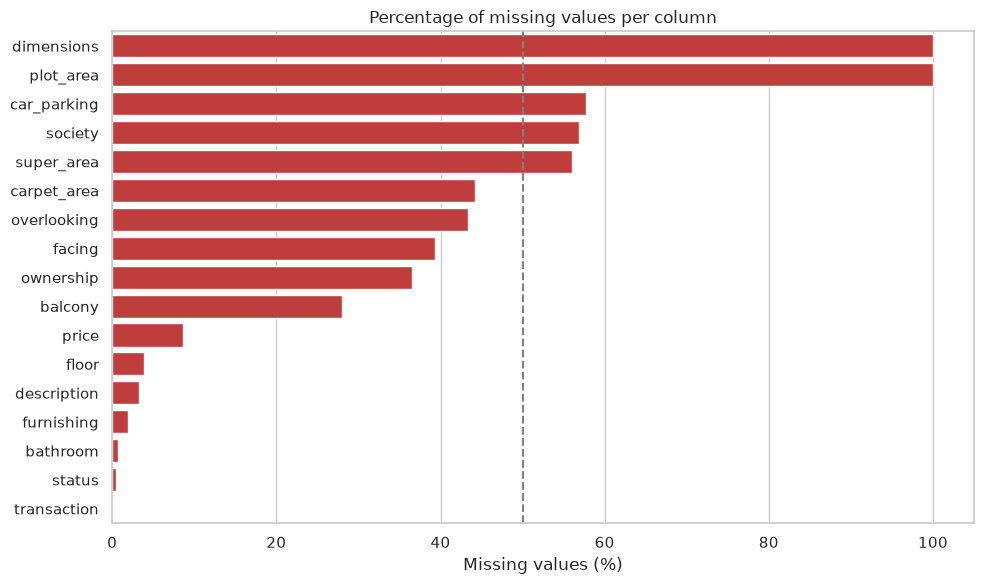

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

**Reading the chart:**
- `dimensions` and `plot_area` are **100% empty**: useless.
- Several columns are **more than 50% empty** (`society`, `super_area`, `car_parking`). We cannot simply delete every row with a missing value: we would lose almost the whole dataset!
- Core columns like `title`, `location` and `amount` are (almost) complete.

💡 **Tip:** there is no single recipe for missing values. For each column we will decide between **dropping the column**, **dropping the rows**, **filling** (*imputing*) the values, or **recovering** them from other columns. We do this step by step in the next sections.

## 1.4 Drop columns we cannot (or will not) use

A column is worth keeping only if it carries information. Let's check the suspicious ones:

In [17]:
# A column with a single value tells us nothing: every flat would be the same
print("Values in 'status':")
print(df_clean["status"].value_counts(dropna=False))   # dropna=False also counts the NaN

# How many different society names are there?
print(f"\nDifferent values in 'society': {df_clean['society'].nunique():,}")

Values in 'status':
status
Ready to Move    67893
NaN                299
Name: count, dtype: int64

Different values in 'society': 10,376


We drop:

| Column | Reason |
|---|---|
| `dimensions`, `plot_area` | 100% missing |
| `status` | Constant: every listing is *"Ready to Move"* |
| `description` | Long free text. Useful for **NLP** (text models), but out of scope today |
| `society` | 58% missing and >10,000 different names: too fragmented to analyse |

⚠️ **Watch out:** dropping a column is a **decision**, not a rule. Always write down *why* you dropped something, so others (and future you) can understand it.

In [18]:
columns_to_drop = ["dimensions", "plot_area", "status", "description", "society"]

df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Remaining columns ({df_clean.shape[1]}): {df_clean.columns.tolist()}")

Remaining columns (15): ['title', 'amount', 'price', 'location', 'carpet_area', 'floor', 'transaction', 'furnishing', 'facing', 'overlooking', 'bathroom', 'balcony', 'car_parking', 'ownership', 'super_area']


## 1.5 Fix inconsistent data types (text → numbers)

This is usually the biggest job. Computers cannot calculate with text: `"42 Lac"` is just a sequence of characters. We have to **convert** each column into proper numbers.

The general strategy:
1. Look at the different formats in the column (`value_counts()`).
2. Write a small **function** that converts *one* value.
3. **Apply** it to the whole column with `.apply()`.
4. **Check** the result.

### 1.5.1 Price: `amount`

Prices use the Indian numbering system: **1 Lakh (Lac) = 100,000 ₹** and **1 Crore (Cr) = 10,000,000 ₹ (= 100 Lakh)**. Some listings say *"Call for Price"* instead of a number.

In [19]:
# What formats are there? Look at the most frequent values
df_clean["amount"].value_counts().head(10)

amount
Call for Price    2937
45 Lac            1692
65 Lac            1628
55 Lac            1533
60 Lac            1425
40 Lac            1361
75 Lac            1333
35 Lac            1313
50 Lac            1297
70 Lac            1194
Name: count, dtype: int64

In [20]:
def parse_amount(text):
    # Convert a price like "42 Lac" or "1.40 Cr" into rupees (a float).
    # Anything that is not a number + unit (e.g. "Call for Price") becomes NaN.
    multipliers = {"Lac": 100_000, "Cr": 10_000_000}

    if pd.isna(text):               # already missing -> stay missing
        return np.nan

    parts = text.strip().split()    # "1.40 Cr " -> ["1.40", "Cr"]
    if len(parts) != 2 or parts[1] not in multipliers:
        return np.nan               # e.g. "Call for Price" -> unknown price

    number, unit = parts
    return float(number) * multipliers[unit]


# Always test a function on a few examples before applying it to the whole column!
for example in ["42 Lac", "1.40 Cr ", "Call for Price"]:
    print(f"{example!r:>18} -> {parse_amount(example)}")

          '42 Lac' -> 4200000.0
        '1.40 Cr ' -> 14000000.0
  'Call for Price' -> nan


In [21]:
df_clean["amount"] = df_clean["amount"].apply(parse_amount)

# Indian prices are easier to read in Lakh, so we keep a second column for plots and tables
df_clean["amount_lakh"] = df_clean["amount"] / 100_000

print(f"dtype is now: {df_clean['amount'].dtype}")
print(f"Listings without a price ('Call for Price'): {df_clean['amount'].isna().sum():,}")
df_clean[["amount", "amount_lakh"]].describe()

dtype is now: float64
Listings without a price ('Call for Price'): 2,937


,amount,amount_lakh
count,"65,255.00","65,255.00"
mean,"10,679,088.19",106.79
std,"62,925,189.86",629.25
min,"100,000.00",1.00
25%,"4,100,000.00",41.00
50%,"6,500,000.00",65.00
75%,"10,900,000.00",109.00
max,"14,003,000,000.00","140,030.00"


### 1.5.2 Floor areas: `carpet_area` and `super_area`

Areas are written as `"<number> <unit>"`, but with **different units**, and some big numbers contain a thousands separator (`"10,000 sqft"`). Mixing units is a classic and dangerous mistake: 100 sqm and 100 sqft are *very* different flats!

In [22]:
# Extract the unit: everything after the number. str.extract uses a regular expression (regex):
#   [\d.,]+  -> one or more digits, dots or commas (the number)
#   \s*      -> optional spaces
#   (\w+)    -> the unit (letters), captured between brackets
carpet_units = df_clean["carpet_area"].str.extract(r"[\d.,]+\s*(\w+)")[0]
carpet_units.value_counts()

0
sqft      36497
sqyrd      1004
sqm         564
marla         3
acre          2
kanal         2
ground        1
cent          1
bigha         1
Name: count, dtype: int64

Almost everything is in **sqft** (square feet), with some **sqyrd** (square yards) and **sqm** (square metres). The rest are rare local Indian units (*marla*, *kanal*, *bigha*…) used for land, appearing in only a handful of rows.

Decision: we convert the three main units to **sqft**, and set the rare units to `NaN` (converting them is not worth the risk of errors for ~20 rows).

| Unit | Conversion to sqft |
|---|---|
| sqft | × 1 |
| sqyrd | × 9 (1 yard = 3 feet → 3 × 3) |
| sqm | × 10.7639 |

In [23]:
SQFT_PER_UNIT = {"sqft": 1.0, "sqyrd": 9.0, "sqm": 10.7639}


def parse_area(text):
    # Convert an area like "1,200 sqft" or "100 sqm" into square feet (float).
    # Unknown or rare units become NaN.
    if pd.isna(text):
        return np.nan

    number, unit = text.split(maxsplit=1)    # "1,200 sqft" -> ["1,200", "sqft"]
    number = float(number.replace(",", ""))  # remove the thousands separator before converting
    unit = unit.strip()

    if unit not in SQFT_PER_UNIT:
        return np.nan
    return number * SQFT_PER_UNIT[unit]


for example in ["500 sqft", "10,000 sqft", "100 sqm", "60 sqyrd", "3 marla"]:
    print(f"{example!r:>15} -> {parse_area(example)}")

     '500 sqft' -> 500.0
  '10,000 sqft' -> 10000.0
      '100 sqm' -> 1076.3899999999999
     '60 sqyrd' -> 540.0
      '3 marla' -> nan


In [24]:
for column in ["carpet_area", "super_area"]:
    df_clean[column] = df_clean[column].apply(parse_area)

# Architects in Europe think in square metres, so we add a m² version as well (1 m² = 10.7639 sqft)
df_clean["carpet_area_m2"] = df_clean["carpet_area"] / 10.7639

df_clean[["carpet_area", "super_area", "carpet_area_m2"]].describe()

,carpet_area,super_area,carpet_area_m2
count,"38,065.00","29,973.00","38,065.00"
mean,"1,314.86","1,404.16",122.15
std,"5,031.91","1,003.39",467.48
min,1.00,1.00,0.09
25%,801.00,925.70,74.42
50%,"1,100.00","1,219.00",102.19
75%,"1,475.00","1,640.00",137.03
max,"709,222.00","40,000.00","65,888.94"


Look at the `min` and `max`: a flat of a few sqft, or of hundreds of thousands of sqft, is not realistic. Those are **outliers** (probably typos), we deal with them in section 1.9.

### 1.5.3 Counts: `bathroom` and `balcony`

These should be integers, but they are text, and the largest category is written as `"> 10"`.

In [25]:
df_clean["bathroom"].value_counts(dropna=False)

bathroom
2       34697
3       19528
1        6959
4        4924
5        1318
NaN       471
6         198
> 10       33
7          31
10         12
8          12
9           9
Name: count, dtype: int64

In [26]:
for column in ["bathroom", "balcony"]:
    # "> 10" is not a number. We replace it with 11 ("more than 10"); it affects very few rows.
    as_text = df_clean[column].replace("> 10", "11")
    # pd.to_numeric converts text to numbers. errors="coerce" turns anything unconvertible into NaN
    # instead of crashing. "Int64" (capital I) is pandas' integer type that ALLOWS missing values.
    df_clean[column] = pd.to_numeric(as_text, errors="coerce").astype("Int64")

df_clean[["bathroom", "balcony"]].dtypes

bathroom    Int64
balcony     Int64
dtype: object

### 1.5.4 Floor level: `floor`

`"10 out of 11"` contains **two** pieces of information: the **floor of the flat** and the **total number of floors** of the building (its height). We split it into two numeric columns.

In [27]:
# Values that do NOT look like "<number> out of <number>"
floor_text = df_clean["floor"].dropna()
floor_text[~floor_text.str.match(r"^\d+ out of \d+$")].value_counts().head(8)

floor
Ground out of 3     1113
Ground out of 4      959
Ground out of 2      536
Ground out of 5      359
Ground out of 1      188
Ground out of 6      126
Ground out of 7       92
Ground out of 10      54
Name: count, dtype: int64

In [28]:
# Split "10 out of 11" into two columns: ["10", "11"]
floor_parts = df_clean["floor"].str.split(" out of ", expand=True)

# Words used for floors below 1. We give basements negative numbers.
floor_words = {"Ground": "0", "Upper Basement": "-1", "Lower Basement": "-2"}

floor_num_text = floor_parts[0].replace(floor_words)
df_clean["floor_num"] = pd.to_numeric(floor_num_text, errors="coerce").astype("Int64")
df_clean["total_floors"] = pd.to_numeric(floor_parts[1], errors="coerce").astype("Int64")

df_clean[["floor", "floor_num", "total_floors"]].sample(5, random_state=RANDOM_STATE)

,floor,floor_num,total_floors
22224,2 out of 15,2,15
61651,4 out of 4,4,4
51470,1 out of 3,1,3
7606,2 out of 4,2,4
53547,5 out of 6,5,6


### 1.5.5 Parking: `car_parking`

Values look like `"1 Covered"`, `"2 Covered,"` (with a stray comma), `"1 Open"`… We keep the **number of parking spaces**: the first number in the text.

In [29]:
# (\d+) captures the first group of digits; [0] takes that captured group
df_clean["parking_spaces"] = pd.to_numeric(
    df_clean["car_parking"].str.extract(r"(\d+)")[0], errors="coerce"
).astype("Int64")

df_clean["parking_spaces"].value_counts(dropna=False).head(8)

parking_spaces
<NA>    39329
1       23325
2        4228
3         528
4         152
5          66
10         49
6          36
Name: count, dtype: Int64

## 1.6 Feature engineering

**Feature engineering** means creating new, more useful columns from the existing ones. This is where domain knowledge (yours, as architects!) is very valuable.

### 1.6.1 Typology from the title

The number of bedrooms is hidden in the title: *"**2 BHK** Ready to Occupy **Flat** for sale in…"*. We extract it with regular expressions.

In [30]:
df_clean["title"].head(3).tolist()

['1 BHK Ready to Occupy Flat for sale in Srushti Siddhi Mangal Murti Complex Bhiwandi',
 '2 BHK Ready to Occupy Flat for sale in Dosti Vihar Pokhran Road',
 '2 BHK Ready to Occupy Flat for sale in Sunrise by Kalpataru Kolshet Road']

In [31]:
# ^(\d+) BHK -> digits at the start of the text, followed by " BHK"
df_clean["bhk"] = pd.to_numeric(
    df_clean["title"].str.extract(r"^(\d+) BHK")[0], errors="coerce"
).astype("Int64")

# The type of property is one of these words in the title
df_clean["property_type"] = df_clean["title"].str.extract(r"(Flat|Studio|Apartment|Villa|House|Penthouse)")[0]

print(df_clean["bhk"].value_counts(dropna=False).sort_index())
print()
print(df_clean["property_type"].value_counts(dropna=False))

bhk
1        5998
2       26578
3       28621
4        5917
5         584
6          90
7          18
8          12
9           7
10         11
<NA>      356
Name: count, dtype: Int64

property_type
Flat         67867
Studio         296
Apartment       27
NaN              2
Name: count, dtype: int64


### 1.6.2 Relative floor position

A 5th floor is the *top* of a 5-storey building but the *bottom* of a 30-storey tower. Dividing the floor by the building height gives a **relative position** between 0 (ground) and 1 (top floor).

In [32]:
df_clean["floor_ratio"] = df_clean["floor_num"] / df_clean["total_floors"]

# Basements give negative ratios and typos can give values > 1 (floor 12 of 10).
# .where(condition) keeps values where the condition is True and sets the rest to NaN.
df_clean["floor_ratio"] = df_clean["floor_ratio"].where(df_clean["floor_ratio"].between(0, 1))

df_clean["floor_ratio"].describe()

count   65,176.00
mean         0.53
std          0.29
min          0.00
25%          0.29
50%          0.50
75%          0.75
max          1.00
Name: floor_ratio, dtype: Float64

## 1.7 Clean the categorical columns

**Categorical** columns contain a limited set of labels (e.g. *Furnished / Unfurnished*). Typical problems: rare or irrelevant categories, inconsistent spelling, and missing labels.

In [33]:
for column in ["transaction", "furnishing", "facing", "ownership"]:
    print(df_clean[column].value_counts(dropna=False), end="\n\n")

transaction
Resale          50614
New Property    17438
NaN                78
Other              60
Rent/Lease          2
Name: count, dtype: int64

furnishing
Semi-Furnished    29248
Unfurnished       28537
Furnished          9117
NaN                1290
Name: count, dtype: int64

facing
NaN             26800
East            19000
North - East     8644
North            5642
West             3301
South            1689
South - East     1256
North - West     1189
South -West       671
Name: count, dtype: int64

ownership
Freehold                37341
NaN                     24928
Leasehold                3070
Co-operative Society     2370
Power Of Attorney         483
Name: count, dtype: int64



What we will do:
- **`transaction`**: this is a *for sale* dataset, so the 2 *"Rent/Lease"* listings do not belong here: we remove them.
- **`facing`**: the spelling is inconsistent (`"North - East"` vs `"South -West"`). We standardise it to `"North-East"`, `"South-West"`…
- **Missing labels**: we fill them with `"Unknown"` instead of guessing.

💡 **Tip:** filling a category with `"Unknown"` is honest: we keep the row, and *"the seller did not say"* can itself be information (maybe sellers hide orientation when it is bad!). Filling it with the most frequent value (e.g. *"East"*) would invent facts.

In [34]:
# 1) Remove rent/lease listings. ~ means "NOT", so we keep the rows that are NOT rent/lease
rows_before = len(df_clean)
df_clean = df_clean[~(df_clean["transaction"] == "Rent/Lease")].reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean)} rent/lease listings")

# 2) Standardise the spelling of orientations: remove spaces around "-"
df_clean["facing"] = df_clean["facing"].str.replace(r"\s*-\s*", "-", regex=True)

# 3) Fill missing labels with "Unknown"
for column in ["transaction", "furnishing", "facing", "ownership"]:
    df_clean[column] = df_clean[column].fillna("Unknown")

df_clean["facing"].value_counts()

Removed 2 rent/lease listings


facing
Unknown       26800
East          19000
North-East     8643
North          5642
West           3301
South          1688
South-East     1256
North-West     1189
South-West      671
Name: count, dtype: int64

**`overlooking`** (the views) is special: one cell can contain **several values**, e.g. *"Garden/Park, Pool, Main Road"*. We cannot analyse it as one category, so we create one **True/False column per view**. This is called **one-hot encoding**, and you will use it a lot in machine learning.

In [35]:
df_clean["overlooking"].value_counts().head(6)

overlooking
Main Road                       12244
Garden/Park, Main Road           8875
Garden/Park                      8268
Garden/Park, Pool, Main Road     4735
Pool, Garden/Park, Main Road     1593
Garden/Park, Pool                1383
Name: count, dtype: int64

In [36]:
# .str.contains() returns True if the text contains the word.
# na=False: if overlooking is missing, we treat the view as "not mentioned" (False)
df_clean["view_garden"] = df_clean["overlooking"].str.contains("Garden", na=False)
df_clean["view_pool"] = df_clean["overlooking"].str.contains("Pool", na=False)
df_clean["view_main_road"] = df_clean["overlooking"].str.contains("Main Road", na=False)

df_clean[["overlooking", "view_garden", "view_pool", "view_main_road"]].head()

,overlooking,view_garden,view_pool,view_main_road
0,NaN,False,False,False
1,Garden/Park,True,False,False
2,Garden/Park,True,False,False
3,NaN,False,False,False
4,"Garden/Park, Main Road",True,False,True


Finally, the city names are written like URLs (`"new-delhi"`). We make them readable (`"New Delhi"`):

In [37]:
df_clean["location"] = df_clean["location"].str.replace("-", " ").str.title()

print(f"Number of cities: {df_clean['location'].nunique()}")
df_clean["location"].value_counts().head()

Number of cities: 81


location
Faridabad        3000
Greater Noida    3000
Chennai          2999
Gurgaon          2998
New Delhi        2998
Name: count, dtype: int64

## 1.8 Detective work: what is the `price` column?

We have two price columns: `amount` (the price of the flat) and the mysterious `price` (median ≈ 6,000 ₹). 6,000 ₹ is far too cheap for a flat… but it is a very plausible price **per square foot** in India.

Let's test that hypothesis: if `price` is a price per sqft, then `amount / area` should be equal to `price`, so the ratio `(amount / area) / price` should be ≈ 1.

In [38]:
# Compare against both areas. Rows with missing values give NaN and are ignored by .median()
ratio_carpet = (df_clean["amount"] / df_clean["carpet_area"]) / df_clean["price"]
ratio_super = (df_clean["amount"] / df_clean["super_area"]) / df_clean["price"]

print(f"amount / carpet_area / price -> median ratio {ratio_carpet.median():.3f}")
print(f"amount / super_area  / price -> median ratio {ratio_super.median():.3f}")
# .dropna() keeps only the rows where the ratio could be computed (both values present)
print(f"Rows where the super-area ratio is within 1% of 1: {ratio_super.dropna().between(0.99, 1.01).mean():.1%}")

amount / carpet_area / price -> median ratio 1.216
amount / super_area  / price -> median ratio 1.000
Rows where the super-area ratio is within 1% of 1: 100.0%


Mystery solved! `price` is the **price per sqft of super (gross) area**: the ratio is exactly 1. Against the carpet (net) area the ratio is ~1.2, because the gross area is ~20% larger than the net area.

We rename the column to say what it really is. Now we also have a nice bonus: since `price_per_sqft = amount / super_area`, we can **recover** the missing super areas: `super_area = amount / price_per_sqft`.

💡 **Tip:** recovering missing values from an exact relationship between columns is the best kind of "imputation": we are not guessing, we are calculating.

In [39]:
df_clean = df_clean.rename(columns={"price": "price_per_sqft"})

# price_per_sqft of 0 would mean division by zero: treat it as missing
df_clean["price_per_sqft"] = df_clean["price_per_sqft"].replace(0, np.nan)

missing_before = df_clean["super_area"].isna().sum()
recovered_super_area = df_clean["amount"] / df_clean["price_per_sqft"]
df_clean["super_area"] = df_clean["super_area"].fillna(recovered_super_area)
missing_after = df_clean["super_area"].isna().sum()

print(f"Missing super_area before: {missing_before:,} ({missing_before / len(df_clean):.0%})")
print(f"Missing super_area after:  {missing_after:,} ({missing_after / len(df_clean):.0%})")

Missing super_area before: 38,218 (56%)
Missing super_area after:  4,422 (6%)


With both areas available, we can compute a metric every architect knows: the **efficiency ratio** (net-to-gross), **carpet area ÷ super area**. It tells us how much of the area you pay for is actually usable inside the flat. Physically it must be ≤ 1 (the usable area cannot be bigger than the gross area), so values above 1 are errors.

In [40]:
df_clean["efficiency"] = df_clean["carpet_area"] / df_clean["super_area"]

n_impossible = (df_clean["efficiency"] > 1).sum()
print(f"Listings with an impossible efficiency > 1: {n_impossible:,}")

# Keep only physically plausible values (between 0.3 and 1); everything else becomes NaN
df_clean["efficiency"] = df_clean["efficiency"].where(df_clean["efficiency"].between(0.3, 1))
df_clean["efficiency"].describe()

Listings with an impossible efficiency > 1: 2,284


count   31,339.00
mean         0.81
std          0.12
min          0.30
25%          0.72
50%          0.81
75%          0.90
max          1.00
Name: efficiency, dtype: float64

## 1.9 Outliers

An **outlier** is a value far away from the rest. There are two very different kinds:
- **Errors**: typos, wrong units, a price written in rupees instead of Lakh… → should be removed or corrected.
- **Genuine extremes**: a real penthouse worth 50 Crore → real, but rare. Whether to keep them depends on the question.

The **boxplot** is the classic tool to spot them. The box contains the middle 50% of the data, the line inside is the median, and the dots are the points the boxplot considers "extreme".

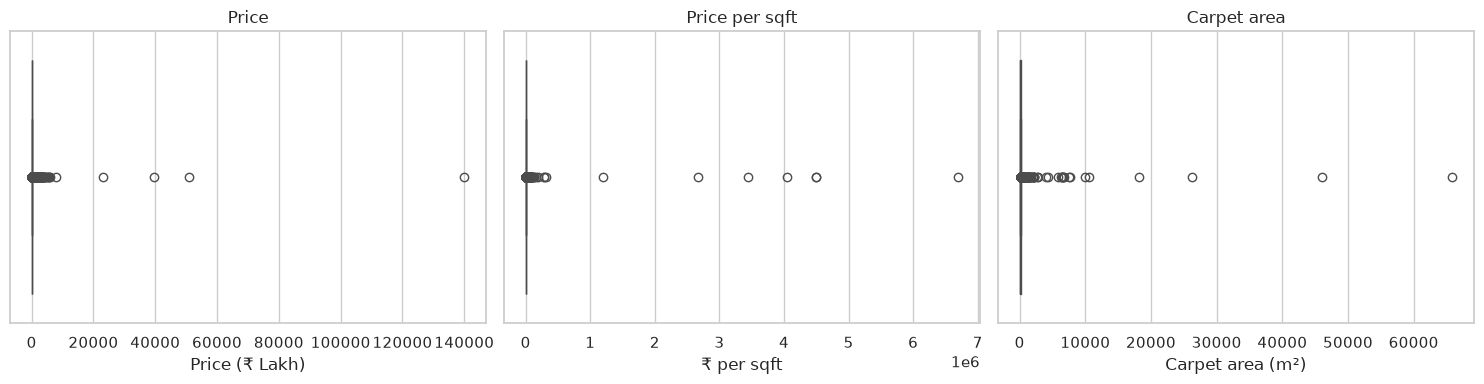

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["amount_lakh"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (₹ Lakh)")

sns.boxplot(x=df_clean["price_per_sqft"], ax=axes[1])
axes[1].set_title("Price per sqft")
axes[1].set_xlabel("₹ per sqft")

sns.boxplot(x=df_clean["carpet_area_m2"], ax=axes[2])
axes[2].set_title("Carpet area")
axes[2].set_xlabel("Carpet area (m²)")

plt.tight_layout()
plt.show()

The boxes are squashed into a thin line on the left, because a few **absurd values** stretch the axis: flats of tens of thousands of m², or prices per sqft in the millions. These are clearly errors.

**How do we decide what is an outlier?** Two common rules:
1. **IQR rule** (the one boxplots use): outlier if below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`, with IQR = Q3 − Q1.
2. **Percentile rule**: remove the most extreme 1% on each side (below the 1st percentile or above the 99th).

Let's compare how many listings each rule would remove for the price:

In [42]:
price = df_clean["amount_lakh"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)

# Percentile rule
p01, p99 = price.quantile([0.01, 0.99])
pct_outliers = (price < p01) | (price > p99)

print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} Lakh -> removes {iqr_outliers.sum():,} listings")
print(f"Percentile rule: keep {p01:,.1f} to {p99:,.1f} Lakh -> removes {pct_outliers.sum():,} listings")

IQR rule:        keep -61.0 to 211.0 Lakh -> removes 6,110 listings
Percentile rule: keep 14.0 to 650.0 Lakh -> removes 1,260 listings


House prices are **skewed**: many normal flats and a long tail of expensive ones. The IQR rule assumes a roughly symmetric distribution, so here it would throw away thousands of *genuine* expensive flats. The **percentile rule** is gentler: it only removes the most extreme 1% on each side, which is where the errors are.

⚠️ **Watch out:** there is no "correct" threshold. Whatever you choose, **report it** ("we removed listings below the 1st and above the 99th percentile of price, price per sqft and carpet area").

Before that, one more decision: listings **without a price** (*"Call for Price"*) are useless for our goal, because on Day 2 we want to **predict the price**: a row without the answer cannot teach the model anything. We remove them.

In [43]:
rows_before = len(df_clean)

# 1) Remove listings without a price (our target variable)
df_clean = df_clean.dropna(subset=["amount"])
print(f"Removed {rows_before - len(df_clean):,} listings without a price")


def within_percentiles(series, low=0.01, high=0.99):
    # True for values between the low and high percentiles. Missing values are kept (True):
    # we do not want to delete a row just because one of the columns is unknown.
    lower, upper = series.quantile([low, high])
    return series.isna() | series.between(lower, upper)


# 2) Percentile rule on the three main numeric columns. & means "AND": all three must be OK
keep = (
    within_percentiles(df_clean["amount"])
    & within_percentiles(df_clean["price_per_sqft"])
    & within_percentiles(df_clean["carpet_area"])
)
rows_before_outliers = len(df_clean)
df_clean = df_clean[keep].reset_index(drop=True)
print(f"Removed {rows_before_outliers - len(df_clean):,} outlier listings")
print(f"Rows left: {len(df_clean):,}")

Removed 2,937 listings without a price
Removed 2,575 outlier listings
Rows left: 62,678


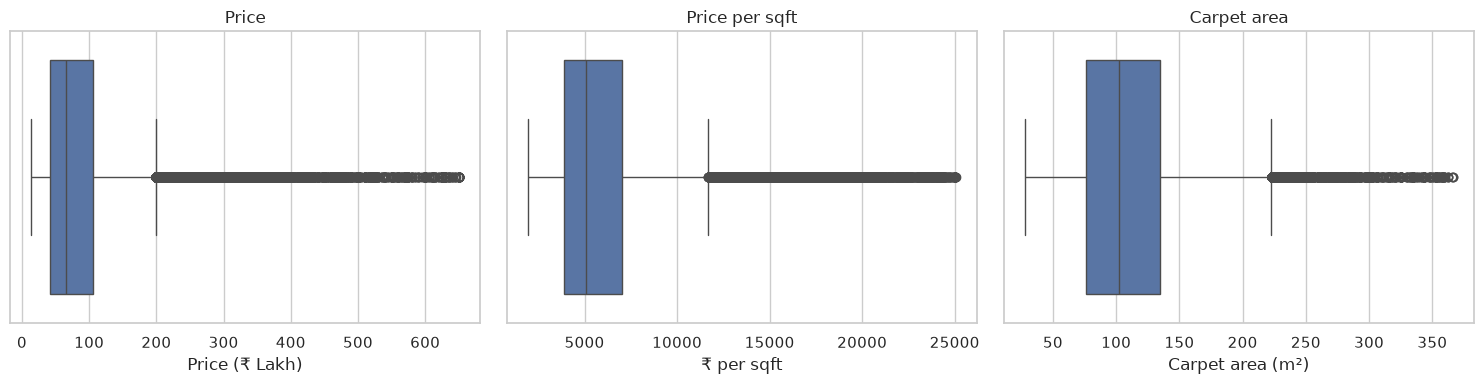

In [44]:
# Same boxplots as before: now we can actually see the distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["amount_lakh"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (₹ Lakh)")

sns.boxplot(x=df_clean["price_per_sqft"], ax=axes[1])
axes[1].set_title("Price per sqft")
axes[1].set_xlabel("₹ per sqft")

sns.boxplot(x=df_clean["carpet_area_m2"], ax=axes[2])
axes[2].set_title("Carpet area")
axes[2].set_xlabel("Carpet area (m²)")

plt.tight_layout()
plt.show()

Much better. There are still dots on the right of the price boxplot, but these are now **genuine expensive flats**, not errors, so we keep them.

## 1.10 Handle the remaining missing values

Let's look at what is still missing:

In [45]:
missing_report(df_clean).head(12)

,n_missing,pct_missing
car_parking,35909,57.29
parking_spaces,35909,57.29
efficiency,32510,51.87
carpet_area_m2,27641,44.10
carpet_area,27641,44.10
overlooking,26629,42.49
balcony,17129,27.33
super_area,2859,4.56
price_per_sqft,2859,4.56
floor_ratio,2758,4.40


Decisions, column by column:

| Column | Missing | Decision | Why |
|---|---|---|---|
| `bhk` | very few | **Drop** those rows | Typology is essential and we cannot guess it |
| `bathroom` | very few | **Fill** with the median for the same `bhk` (pandas) | A 3 BHK usually has more bathrooms than a 1 BHK, so the median of *similar* flats is a better guess than the overall median |
| `balcony` | ~25% | **Fill** with the median + add a *"was missing"* flag (scikit-learn) | Too many to drop, and the fact that it is missing may itself be information (see below) |
| `carpet_area`, `parking_spaces`, `floor_*`… | many | **Keep as NaN** | Too many to fill honestly. Day 2 will show how models deal with them |

We show two ways to fill (**impute**) values: by hand with **pandas**, and with **scikit-learn**, the machine learning library we will use from Day 2.

In [46]:
# Drop rows without a typology
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["bhk"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without BHK")

Removed 218 listings without BHK


### 1.10.1 Imputation with pandas: median per group (`bathroom`)

`groupby("bhk")["bathroom"].transform("median")` returns, **for every row**, the median number of bathrooms of flats with the **same number of bedrooms**. We use it to fill the gaps.

In [47]:
n_missing = df_clean["bathroom"].isna().sum()

median_per_bhk = df_clean.groupby("bhk")["bathroom"].transform("median")
# round() because a median can be x.5, and a flat has whole bathrooms
df_clean["bathroom"] = df_clean["bathroom"].fillna(median_per_bhk.round()).astype("Int64")

print(f"Filled {n_missing:,} missing values in 'bathroom' with the median of flats with the same BHK")

Filled 354 missing values in 'bathroom' with the median of flats with the same BHK


### 1.10.2 Imputation with scikit-learn: `SimpleImputer` (`balcony`)

⚠️ **Watch out:** a missing balcony value might mean *"no balcony"* (0) rather than *"unknown"*. Filling with the median assumes the second. To avoid hiding this, we fill the value **and** keep a new column `balcony_was_missing` (True/False) that remembers which values were invented. A model on Day 2 can then learn whether "not saying" matters.

scikit-learn's `SimpleImputer` does both at once. All scikit-learn tools follow the same pattern, which you will see again and again:
1. **Create** the tool with its settings: `SimpleImputer(strategy="median", add_indicator=True)`
2. **`fit`**: learn from the data (here: compute the median)
3. **`transform`**: apply what was learned (here: fill the gaps)

`fit_transform()` does steps 2 and 3 in one go.

💡 **Tip:** in machine learning, the imputer must be `fit` **only on the training data** and then used to `transform` the test data, otherwise information from the test set leaks into the training. We will see this on Day 2. Today we only explore, so fitting on everything is fine.

In [48]:
from sklearn.impute import SimpleImputer

# strategy="median": fill with the median of the column
# add_indicator=True: also return a True/False column marking the values that were missing
imputer = SimpleImputer(strategy="median", add_indicator=True)

# scikit-learn expects a 2D table (DataFrame) of floats, so we pass [["balcony"]] (double brackets)
balcony_float = df_clean[["balcony"]].astype(float)
result = imputer.fit_transform(balcony_float)   # numpy array: column 0 = filled values, column 1 = indicator

print(f"Median learned by the imputer: {imputer.statistics_[0]}")
print(f"Filled {int(result[:, 1].sum()):,} missing values in 'balcony'")

df_clean["balcony"] = pd.Series(result[:, 0]).astype("Int64")
df_clean["balcony_was_missing"] = result[:, 1].astype(bool)

df_clean[["balcony", "balcony_was_missing"]].value_counts().head(6)

Median learned by the imputer: 2.0
Filled 17,030 missing values in 'balcony'


balcony  balcony_was_missing
2        False                  17598
         True                   17030
1        False                  14443
3        False                   9499
4        False                   3151
5        False                    608
Name: count, dtype: int64

💡 **Tip:** scikit-learn has smarter imputers too: `KNNImputer` fills a value using the most *similar* listings, and `IterativeImputer` predicts the missing value from all the other columns with a small model. They are more powerful but slower and harder to explain: start simple.

## 1.11 Final check and save

Last step: remove the helper columns whose information now lives in cleaner columns (`title` → `bhk`, `floor` → `floor_num`, …), put the columns in a logical order, and compare the result with the raw data.

In [49]:
final_columns = [
    # target (what we will predict on Day 2)
    "amount", "amount_lakh",
    # location
    "location",
    # size and typology
    "bhk", "property_type", "carpet_area", "carpet_area_m2", "super_area", "efficiency",
    "bathroom", "balcony", "balcony_was_missing",
    # position in the building
    "floor_num", "total_floors", "floor_ratio",
    # orientation and views
    "facing", "view_garden", "view_pool", "view_main_road",
    # other characteristics
    "transaction", "furnishing", "ownership", "parking_spaces",
    # derived from the price -> careful on Day 2!
    "price_per_sqft",
]

df_clean = df_clean[final_columns]
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 62460 entries, 0 to 62459
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   amount               62460 non-null  float64
 1   amount_lakh          62460 non-null  float64
 2   location             62460 non-null  str    
 3   bhk                  62460 non-null  Int64  
 4   property_type        62460 non-null  str    
 5   carpet_area          34936 non-null  float64
 6   carpet_area_m2       34936 non-null  float64
 7   super_area           59614 non-null  float64
 8   efficiency           30090 non-null  float64
 9   bathroom             62460 non-null  Int64  
 10  balcony              62460 non-null  Int64  
 11  balcony_was_missing  62460 non-null  bool   
 12  floor_num            60064 non-null  Int64  
 13  total_floors         60022 non-null  Int64  
 14  floor_ratio          59715 non-null  Float64
 15  facing               62460 non-null  str    
 1

In [50]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,"187,531.00","62,460.00"
columns,21.00,24.00
numeric columns,4.00,14.00
average % missing,27.29,9.10
memory (MB),250.80,28.90


In [51]:
clean_path = DATA_DIR / "house_prices_clean.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Clean data saved to {clean_path} ({clean_path.stat().st_size / 1e6:.1f} MB)")

Clean data saved to data/house_prices_clean.csv (9.6 MB)


We now have a dataset with **unique listings, numeric columns, consistent units and categories, no absurd values**, and a documented decision for every missing value.

---
### Your turn: cleaning

1. **Spot check.** Pick 3 random rows of `df_clean` with `df_clean.sample(3)`, find the same listings in the raw `df`, and check by hand that the conversions (price, area, floor) are correct.
2. **Error or extreme?** Find the listing(s) with the most bathrooms *per bedroom* (`bathroom / bhk`). Look at the whole row. Is it a plausible flat or a data error? What would you do with it?
3. **Different decision.** Re-do the balcony step assuming that a missing balcony means **0 balconies**. How much does the average number of balconies change?

In [52]:
# 1. Spot check
# Hint: df_clean.sample(3, random_state=...)

In [53]:
# 2. Error or extreme?
# Hint: create a Series with df_clean["bathroom"] / df_clean["bhk"] and use .sort_values() or .idxmax()

In [54]:
# 3. Different decision
# Hint: you will need the balcony column BEFORE filling. Can you get it again from the raw df?

# 2. Exploratory Data Analysis (EDA)

Now that the data is clean, we can **explore** it: understand how the values are distributed, how the variables relate to each other, and form hypotheses. EDA is like a first site visit: we walk around before we start designing.

We go from simple to complex:
- **Univariate**: one variable at a time (distributions, counts)
- **Bivariate**: two variables together (is price related to area?)
- **Multivariate**: several variables at once (correlations, grids of plots)

💡 **Tip:** a good EDA plot answers **one question**. Write the question first, then choose the plot.

## 2.1 Descriptive statistics

| Statistic | Meaning |
|---|---|
| **mean** | The average. Sensitive to extreme values |
| **50% (median)** | The middle value: half the listings are below, half above. Robust to extremes |
| **std** | Standard deviation: how spread out the values are |
| **25% / 75%** | Quartiles: the middle 50% of the listings lie between them |
| **skewness** | 0 = symmetric; > 0 = long tail to the right (a few very large values) |

In [55]:
key_numeric = ["amount_lakh", "price_per_sqft", "carpet_area_m2", "bhk", "bathroom", "total_floors", "efficiency"]

stats = df_clean[key_numeric].describe().T
stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
amount_lakh,"62,460.00",92.23,85.83,14.00,42.00,65.00,105.00,650.00,2.73
price_per_sqft,"59,614.00","6,028.66","3,363.76","1,960.00","3,868.00","5,058.00","7,000.00","25,054.00",2.10
carpet_area_m2,"34,936.00",112.21,51.83,28.06,76.65,102.19,135.17,366.04,1.36
bhk,"62,460.00",2.55,0.80,1.00,2.00,3.00,3.00,10.00,0.31
bathroom,"62,460.00",2.41,0.83,1.00,2.00,2.00,3.00,11.00,0.90
total_floors,"60,022.00",8.54,6.71,1.00,4.00,5.00,12.00,150.00,1.93
efficiency,"30,090.00",0.81,0.12,0.31,0.72,0.81,0.90,1.00,-0.31


For the price, the **mean is clearly higher than the median** and the skewness is strongly positive. This is typical of prices and incomes: a few very expensive flats pull the average up. That is why, for prices, the **median** is usually the better "typical value".

## 2.2 Univariate analysis: numerical variables

**Question: how are prices distributed?**

A **histogram** splits the values into bins and counts how many listings fall in each. The **KDE** line is a smoothed version of the histogram.

For skewed data a **logarithmic scale** helps a lot: on a log axis, equal distances mean equal *ratios* (10 → 100 → 1,000), so the long tail gets compressed and we can see the shape.

Figure saved to figures/02_price_distribution.png


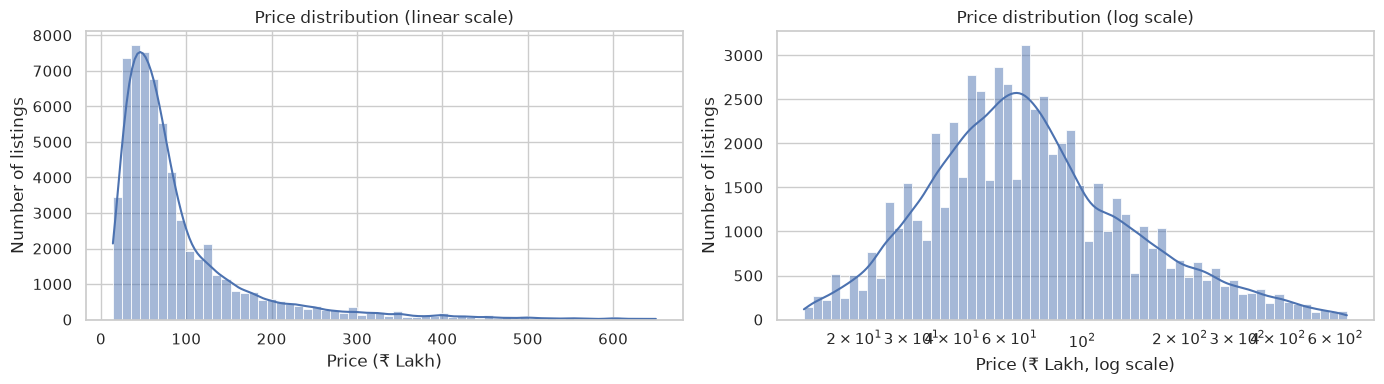

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Linear scale
sns.histplot(df_clean["amount_lakh"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Price distribution (linear scale)")
axes[0].set_xlabel("Price (₹ Lakh)")
axes[0].set_ylabel("Number of listings")

# Log scale: log_scale=True puts the bins on a logarithmic x axis
sns.histplot(df_clean["amount_lakh"], bins=60, kde=True, log_scale=True, ax=axes[1])
axes[1].set_title("Price distribution (log scale)")
axes[1].set_xlabel("Price (₹ Lakh, log scale)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
save_fig("02_price_distribution")
plt.show()

On the linear scale, almost everything is squeezed on the left. On the log scale the price looks like a nice **bell shape** (a *log-normal* distribution). Remember this for Day 2: models often work better if we predict the **log of the price**.

**Question: how big are the flats, and how much does a square foot cost?**

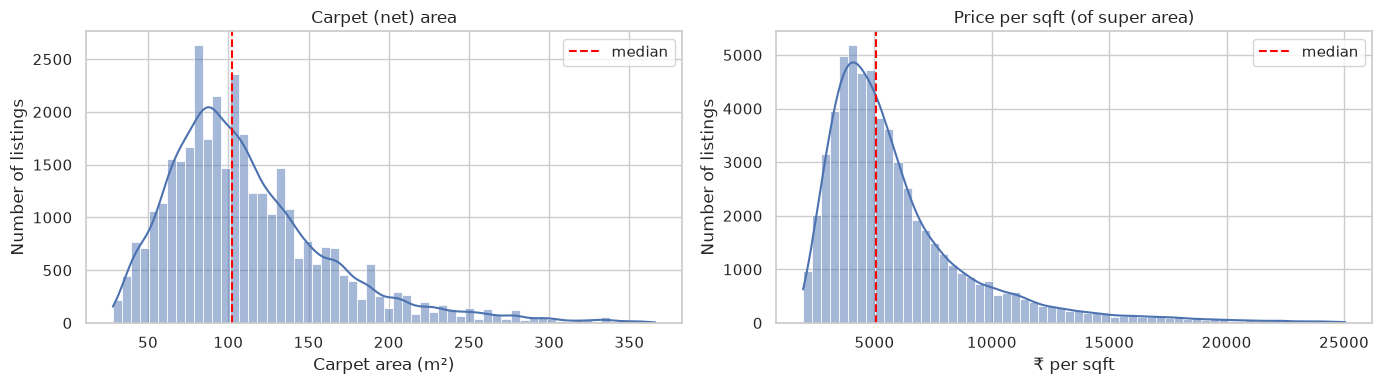

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_clean["carpet_area_m2"], bins=60, kde=True, ax=axes[0])
axes[0].axvline(df_clean["carpet_area_m2"].median(), color="red", linestyle="--", label="median")
axes[0].set_title("Carpet (net) area")
axes[0].set_xlabel("Carpet area (m²)")
axes[0].set_ylabel("Number of listings")
axes[0].legend()

sns.histplot(df_clean["price_per_sqft"], bins=60, kde=True, ax=axes[1])
axes[1].axvline(df_clean["price_per_sqft"].median(), color="red", linestyle="--", label="median")
axes[1].set_title("Price per sqft (of super area)")
axes[1].set_xlabel("₹ per sqft")
axes[1].set_ylabel("Number of listings")
axes[1].legend()

plt.tight_layout()
plt.show()

## 2.3 Univariate analysis: categorical variables

**Question: what kind of flats are on the market?**

For categories we **count** how many listings fall in each one, with `sns.countplot()`. Here we draw four plots in a 2×2 grid with `plt.subplots(2, 2)`.

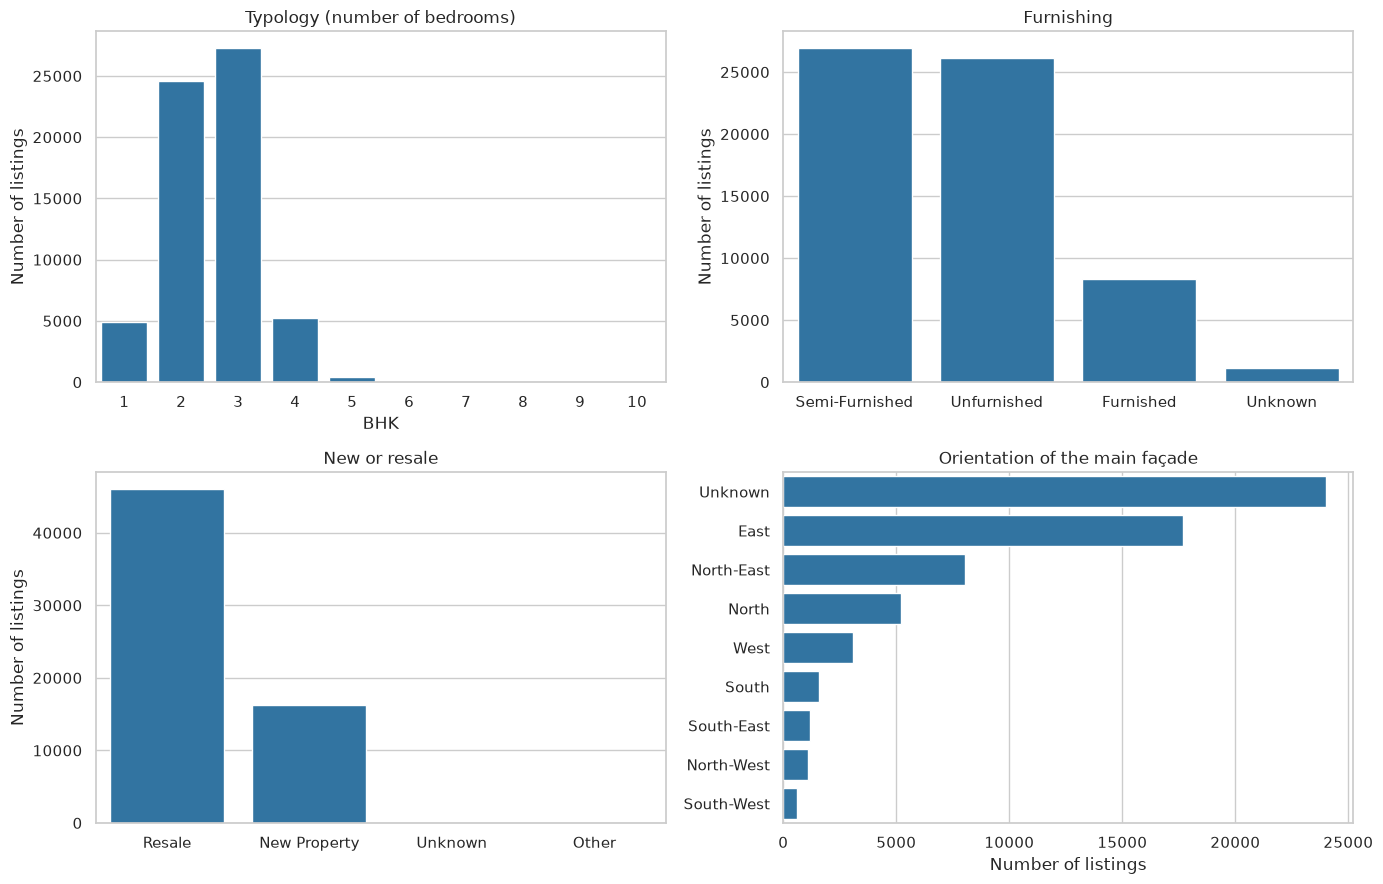

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# axes is a 2x2 grid: axes[row, column]
sns.countplot(data=df_clean, x="bhk", color="tab:blue", ax=axes[0, 0])
axes[0, 0].set_title("Typology (number of bedrooms)")
axes[0, 0].set_xlabel("BHK")

# order=... sorts the bars from most to least frequent
sns.countplot(data=df_clean, x="furnishing", order=df_clean["furnishing"].value_counts().index,
              color="tab:blue", ax=axes[0, 1])
axes[0, 1].set_title("Furnishing")
axes[0, 1].set_xlabel("")

sns.countplot(data=df_clean, x="transaction", order=df_clean["transaction"].value_counts().index,
              color="tab:blue", ax=axes[1, 0])
axes[1, 0].set_title("New or resale")
axes[1, 0].set_xlabel("")

sns.countplot(data=df_clean, y="facing", order=df_clean["facing"].value_counts().index,
              color="tab:blue", ax=axes[1, 1])
axes[1, 1].set_title("Orientation of the main façade")
axes[1, 1].set_ylabel("")

for ax in axes.flat:   # same y-label for the three vertical bar charts
    if ax is not axes[1, 1]:
        ax.set_ylabel("Number of listings")
axes[1, 1].set_xlabel("Number of listings")

plt.tight_layout()
plt.show()

The market is dominated by **2 and 3 BHK** flats, mostly **resale**. Most listings face **East** or **North-East**, but for many the orientation is *Unknown*.

🤔 **Think about it:** is the strong preference for East-facing flats a coincidence? (Hint: search for *Vastu Shastra*, the traditional Indian architecture principles.)

**Question: which cities are in the dataset?**

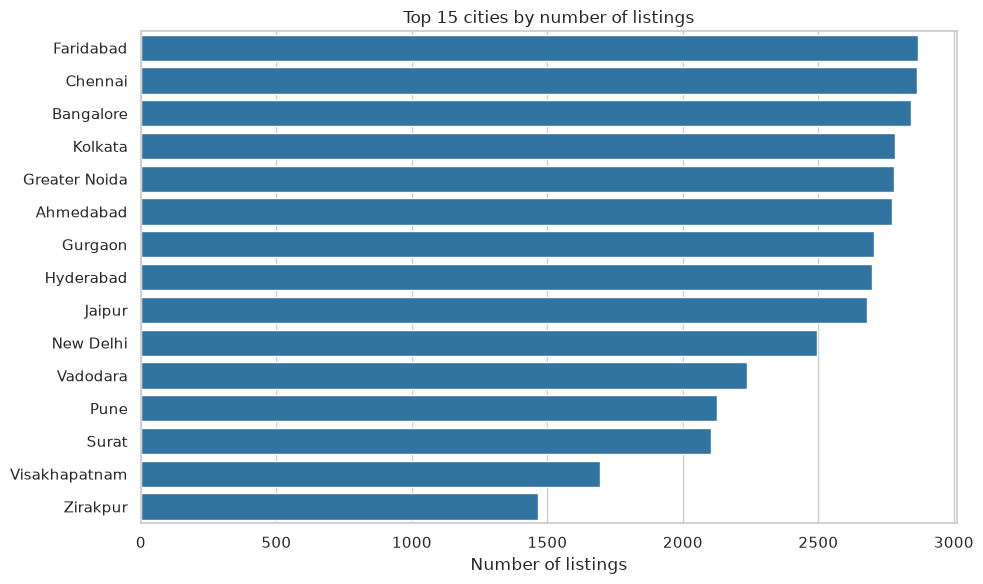

The top 15 cities contain 59% of all listings


In [59]:
top_cities = df_clean["location"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_cities.values, y=top_cities.index, color="tab:blue", ax=ax)
ax.set_title("Top 15 cities by number of listings")
ax.set_xlabel("Number of listings")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

print(f"The top 15 cities contain {top_cities.sum() / len(df_clean):.0%} of all listings")

Surprise: the top cities all have almost **the same number of listings** (~2,500–2,900 each), and the top 15 hold only ~60% of the data. In reality New Delhi has many more flats for sale than Jaipur! The scraper probably collected a **fixed number of listings per city**.

🤔 **Think about it:** this is a form of **sampling bias**. A small city weighs as much as a megacity in every "national" average we compute. The dataset is good for **comparing cities**, but not for describing "the Indian housing market" as a whole.

## 2.4 Bivariate analysis: design questions

Now we look at **two variables at a time**. Let's start with the most obvious relation.

**Question: do bigger flats cost more?**

A **scatter plot** shows each listing as a point. With tens of thousands of points the plot becomes a black blob, so we:
- plot a **random sample** of 5,000 listings,
- make the points semi-transparent (`alpha`),
- use **log scales** (both variables are skewed),
- colour the points by typology (`hue="bhk"`).

Figure saved to figures/03_area_vs_price.png


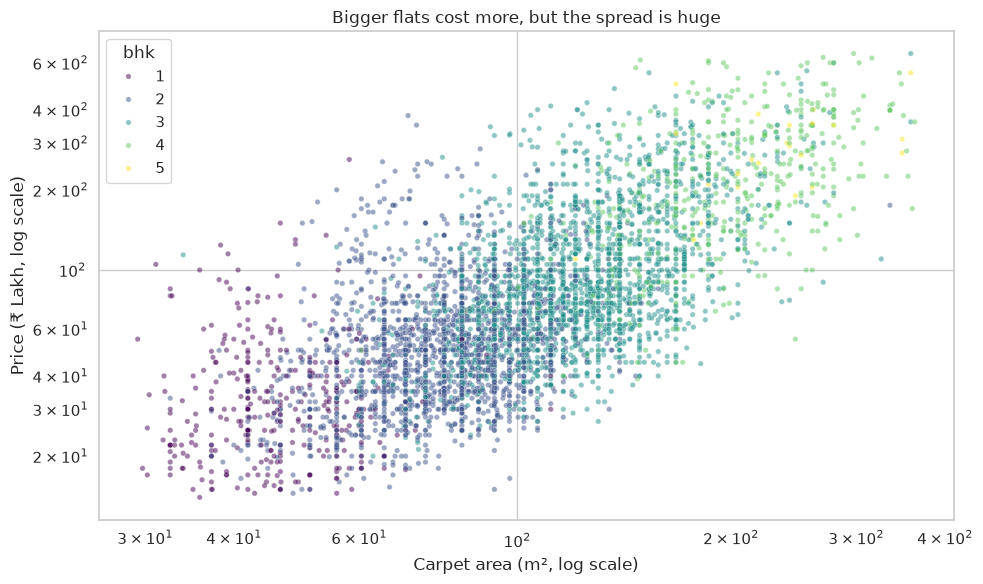

In [60]:
sample = df_clean.dropna(subset=["carpet_area_m2"]).sample(5000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample[sample["bhk"] <= 5], x="carpet_area_m2", y="amount_lakh",
                hue="bhk", palette="viridis", alpha=0.5, s=15, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Bigger flats cost more, but the spread is huge")
ax.set_xlabel("Carpet area (m², log scale)")
ax.set_ylabel("Price (₹ Lakh, log scale)")
plt.tight_layout()
save_fig("03_area_vs_price")
plt.show()

There is a clear **positive relation**: bigger → more expensive. But for the same area, prices vary by a factor of 10 or more! Area alone does not explain the price. The most likely reason: **location**.

**Question: how much does a square foot cost in each city?**

A **boxplot per category** compares distributions side by side. We sort the cities by their median so the plot reads like a ranking. `showfliers=False` hides the outlier dots to keep the plot readable.

Figure saved to figures/04_price_per_sqft_by_city.png


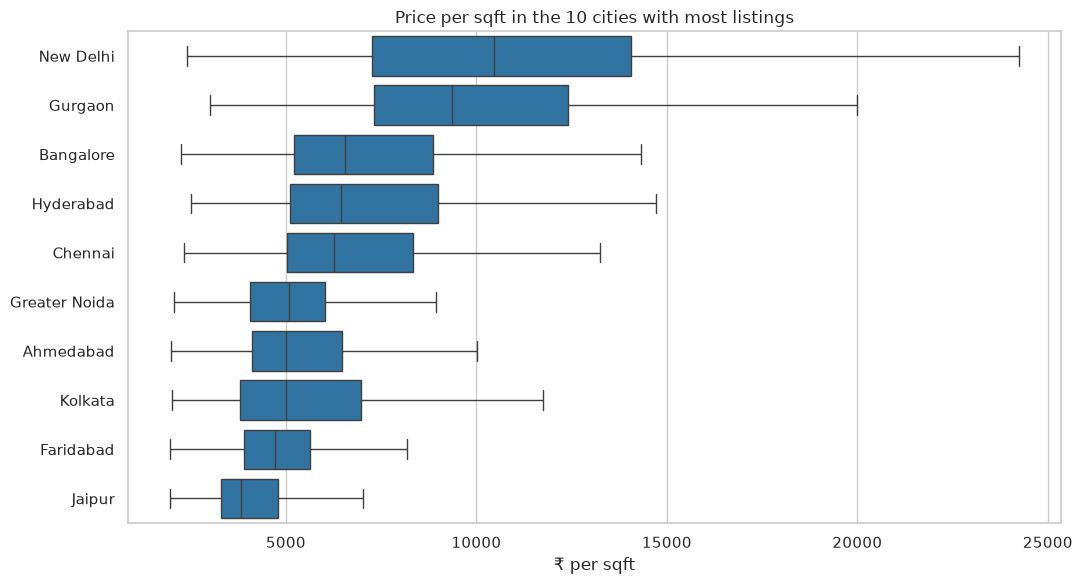

In [61]:
top10_cities = df_clean["location"].value_counts().head(10).index
in_top10 = df_clean[df_clean["location"].isin(top10_cities)]

# Order the cities from most to least expensive (by median price per sqft)
city_order = in_top10.groupby("location")["price_per_sqft"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=in_top10, x="price_per_sqft", y="location", order=city_order,
            showfliers=False, color="tab:blue", ax=ax)
ax.set_title("Price per sqft in the 10 cities with most listings")
ax.set_xlabel("₹ per sqft")
ax.set_ylabel("")
plt.tight_layout()
save_fig("04_price_per_sqft_by_city")
plt.show()

Location is everything: a square foot in the most expensive city costs several times what it costs in the cheapest one.

⚠️ **Watch out – confounding:** this matters for every design question below. Suppose East-facing flats look more expensive. Is it because of the orientation, or because East-facing flats are more common in expensive cities? Location is a **confounder**: it influences both.

A simple fix: compare each flat with **its own city**. We create a **relative price**: the flat's price per sqft divided by the median price per sqft of its city.
- `1.0` → typical for its city
- `1.2` → 20% more expensive than the city median
- `0.8` → 20% cheaper

In [62]:
city_median = df_clean.groupby("location")["price_per_sqft"].transform("median")
df_clean["relative_price"] = df_clean["price_per_sqft"] / city_median

df_clean["relative_price"].describe()

count   59,614.00
mean         1.09
std          0.41
min          0.20
25%          0.82
50%          1.00
75%          1.25
max          7.53
Name: relative_price, dtype: float64

**Question: does orientation change the value?**

A **bar plot** with `estimator="median"` shows the median relative price per orientation. The dashed line at 1.0 is "typical for its city".

Figure saved to figures/05_orientation_vs_price.png


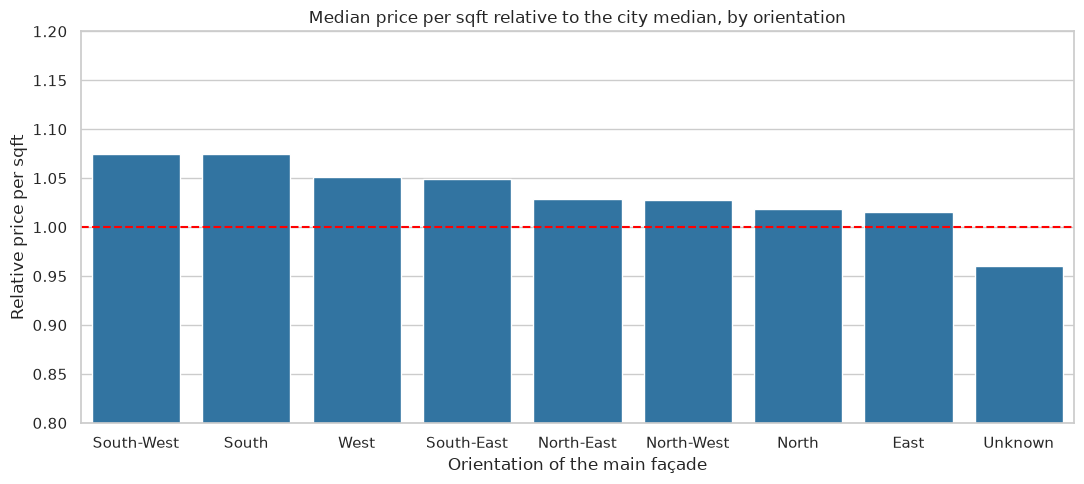

,median,count
facing,,
South-West,1.07,595
South,1.07,1498
West,1.05,2919
South-East,1.05,1126
North-East,1.03,7888
North-West,1.03,1065
North,1.02,5012
East,1.02,17054
Unknown,0.96,22457


In [63]:
facing_order = df_clean.groupby("facing")["relative_price"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5))
# errorbar=None: no error bars (with this many listings they would be tiny anyway)
sns.barplot(data=df_clean, x="facing", y="relative_price", order=facing_order,
            estimator="median", errorbar=None, color="tab:blue", ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_ylim(0.8, 1.2)   # zoom in around 1.0 so differences are visible
ax.set_title("Median price per sqft relative to the city median, by orientation")
ax.set_xlabel("Orientation of the main façade")
ax.set_ylabel("Relative price per sqft")
plt.tight_layout()
save_fig("05_orientation_vs_price")
plt.show()

# The underlying numbers, as a table
df_clean.groupby("facing")["relative_price"].agg(["median", "count"]).sort_values("median", ascending=False)

⚠️ **Watch out:** we zoomed the y axis in to 0.8–1.2, which makes small differences look big. Always check the axis! A difference of a few % may be real, but it is small compared to the difference between cities.

**Question: do views change the value?**

For each view we compare the median relative price of listings **with** and **without** it. We first reshape the data with `melt()`, which turns the three view columns into two columns (`view`, `has_view`). This *long format* is what seaborn likes.

In [64]:
views_long = df_clean.melt(
    id_vars="relative_price",                                  # column to keep as is
    value_vars=["view_garden", "view_pool", "view_main_road"],  # columns to stack
    var_name="view",                                            # name of the new "which column" column
    value_name="has_view",                                      # name of the new "value" column
)
views_long.head()

,relative_price,view,has_view
0,0.60,view_garden,False
1,1.39,view_garden,True
2,1.76,view_garden,True
3,NaN,view_garden,False
4,1.89,view_garden,True


Figure saved to figures/06_views_vs_price.png


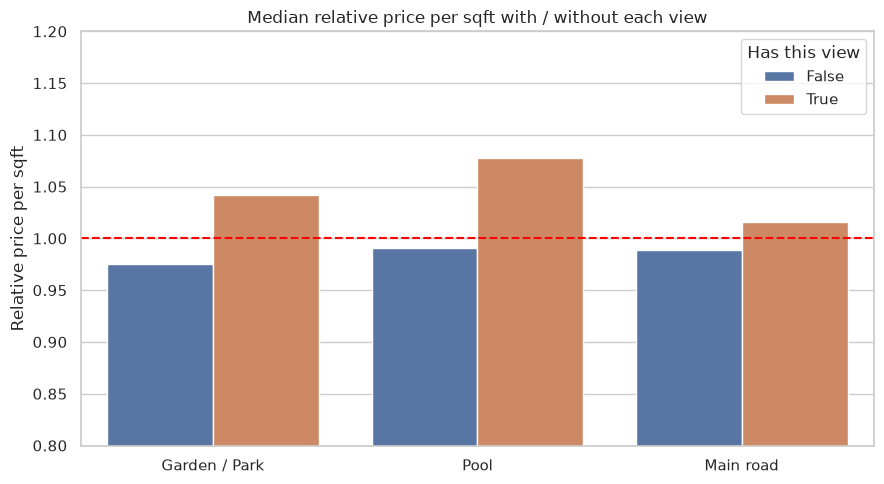

In [65]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=views_long, x="view", y="relative_price", hue="has_view",
            estimator="median", errorbar=None, ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_ylim(0.8, 1.2)
ax.set_title("Median relative price per sqft with / without each view")
ax.set_xlabel("")
ax.set_xticks(range(3), ["Garden / Park", "Pool", "Main road"])
ax.set_ylabel("Relative price per sqft")
ax.legend(title="Has this view")
plt.tight_layout()
save_fig("06_views_vs_price")
plt.show()

🤔 **Think about it:** a pool view probably does not *cause* a higher price by itself. Flats overlooking a pool are usually in **gated complexes with amenities**, which are more expensive anyway. Again: **correlation is not causation**.

**Question: is there a premium for living higher up?**

`floor_ratio` is continuous; to compare groups we **bin** it into categories with `pd.cut()`.

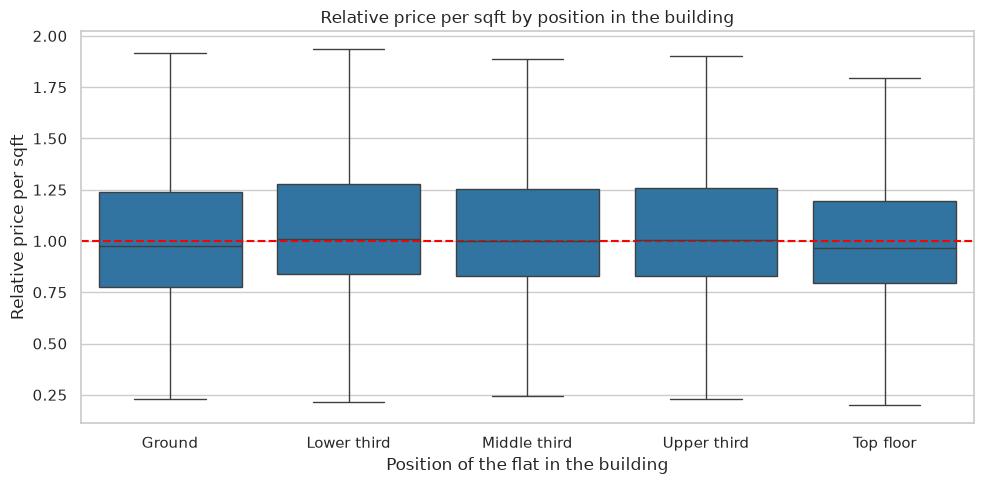

floor_position
Ground           3364
Lower third     12614
Middle third    21969
Upper third     13847
Top floor        7921
Name: count, dtype: int64

In [66]:
# Bins: (-0.01, 0] = ground floor, (0, 0.33] = lower third, ... , (0.99, 1] = top floor
df_clean["floor_position"] = pd.cut(
    df_clean["floor_ratio"],
    bins=[-0.01, 0, 0.33, 0.66, 0.99, 1],
    labels=["Ground", "Lower third", "Middle third", "Upper third", "Top floor"],
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_clean, x="floor_position", y="relative_price", showfliers=False, color="tab:blue", ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_title("Relative price per sqft by position in the building")
ax.set_xlabel("Position of the flat in the building")
ax.set_ylabel("Relative price per sqft")
plt.tight_layout()
plt.show()

df_clean["floor_position"].value_counts().sort_index()

The medians are all very close to 1: **no clear height premium** in this data. Ground and top floors are slightly *cheaper* than the middle of the building, which matches what architects know: ground floors lack privacy and light, top floors suffer from heat and leaks under the roof (especially in a hot climate).

**Question: are new flats and furnished flats more expensive?**

We put both plots side by side. Note `sharey=True`: both plots use the same y axis, so they are directly comparable.

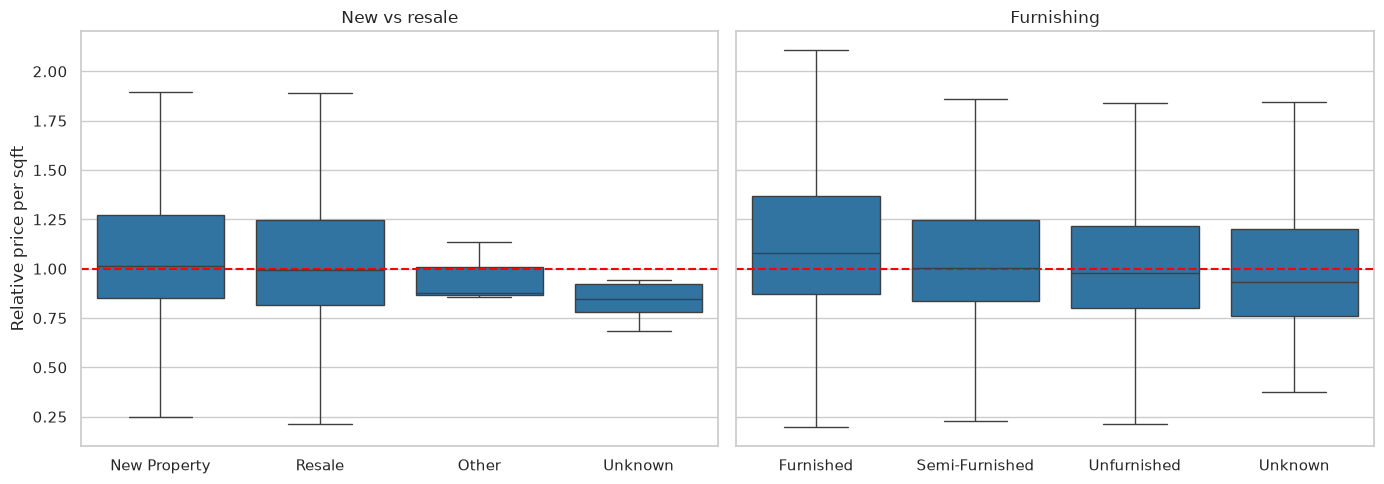

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.boxplot(data=df_clean, x="transaction", y="relative_price", showfliers=False,
            order=["New Property", "Resale", "Other", "Unknown"], color="tab:blue", ax=axes[0])
axes[0].set_title("New vs resale")
axes[0].set_xlabel("")
axes[0].set_ylabel("Relative price per sqft")

sns.boxplot(data=df_clean, x="furnishing", y="relative_price", showfliers=False,
            order=["Furnished", "Semi-Furnished", "Unfurnished", "Unknown"], color="tab:blue", ax=axes[1])
axes[1].set_title("Furnishing")
axes[1].set_xlabel("")

for ax in axes:
    ax.axhline(1, color="red", linestyle="--")

plt.tight_layout()
plt.show()

Furnished flats are a bit more expensive per sqft (you also buy the furniture!), and new flats only slightly more than resale. Notice a pattern across all the plots: listings with **"Unknown"** values are consistently **cheaper**. Sellers of cheaper flats fill in fewer details. So **missingness is information**, which is exactly why we kept "Unknown" as a category and added `balcony_was_missing`.

## 2.5 Summary tables with `groupby` and `crosstab`

Plots are great for seeing patterns, tables are great for exact numbers. Two essential pandas tools:
- **`groupby(...).agg(...)`**: split the data into groups and compute statistics for each group ("split – apply – combine").
- **`pd.crosstab()`**: count how often each *combination* of two categories occurs.

In [68]:
city_summary = (
    df_clean.groupby("location")
    .agg(
        listings=("amount", "count"),                  # (column, statistic)
        median_price_lakh=("amount_lakh", "median"),
        median_price_per_sqft=("price_per_sqft", "median"),
        median_area_m2=("carpet_area_m2", "median"),
        share_new=("transaction", lambda s: (s == "New Property").mean()),  # custom statistic
    )
    .sort_values("listings", ascending=False)
)

city_summary.head(10)

,listings,median_price_lakh,median_price_per_sqft,median_area_m2,share_new
location,,,,,
Faridabad,2868,75.00,"4,727.00",132.39,0.33
Chennai,2863,67.00,"6,256.50",88.26,0.33
Bangalore,2843,85.00,"6,563.00",104.98,0.28
Kolkata,2782,52.00,"5,000.00",81.29,0.18
Greater Noida,2781,63.80,"5,092.50",97.55,0.33
Ahmedabad,2773,70.00,"5,000.00",97.55,0.18
Gurgaon,2706,190.00,"9,355.00",165.14,0.39
Hyderabad,2699,90.00,"6,441.00",115.94,0.25
Jaipur,2680,52.50,"3,820.00",103.59,0.58


In [69]:
# normalize="index" turns counts into shares per row: each row sums to 1 (100%)
typology_vs_furnishing = pd.crosstab(
    df_clean["bhk"], df_clean["furnishing"], normalize="index"
)
# Show as rounded percentages, only for 1-5 BHK
(typology_vs_furnishing.loc[1:5] * 100).round(0)

furnishing,Furnished,Semi-Furnished,Unfurnished,Unknown
bhk,,,,
1,13.00,33.00,52.00,2.00
2,13.00,40.00,45.00,2.00
3,13.00,47.00,38.00,2.00
4,14.00,50.00,35.00,1.00
5,19.00,39.00,39.00,3.00


## 2.6 Correlation

The **correlation coefficient** measures how strongly two numeric variables move together, from **−1** (one goes up, the other goes down) through **0** (no relation) to **+1** (they go up together).

We use **Spearman** correlation instead of the default (Pearson): it works with the *ranking* of the values, so it is not fooled by skewed distributions and outliers.

A **heatmap** shows the whole correlation matrix as colours. The matrix is symmetric (corr(A, B) = corr(B, A)), so we hide the upper triangle with a **mask**.

Figure saved to figures/07_correlation_heatmap.png


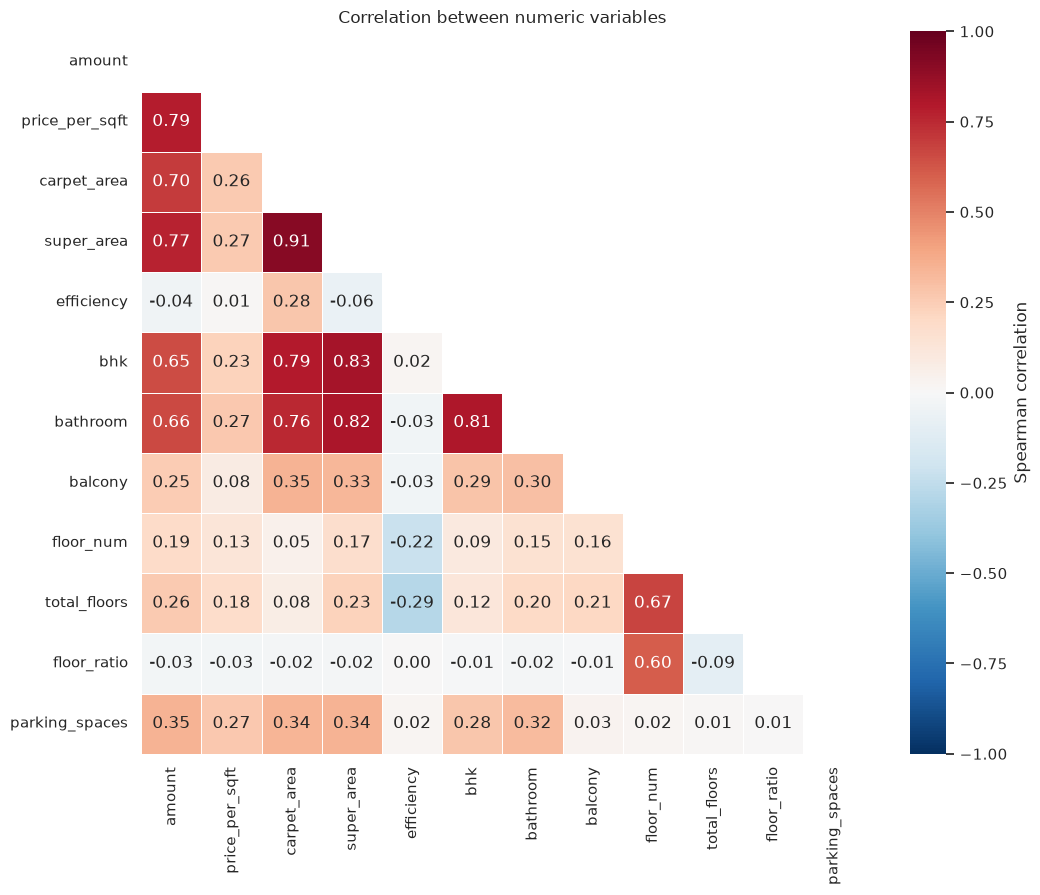

price_per_sqft    0.79
super_area        0.77
carpet_area       0.70
bathroom          0.66
bhk               0.65
parking_spaces    0.35
total_floors      0.26
balcony           0.25
floor_num         0.19
floor_ratio      -0.03
efficiency       -0.04
Name: amount, dtype: float64

In [70]:
corr_columns = [
    "amount", "price_per_sqft", "carpet_area", "super_area", "efficiency", "bhk",
    "bathroom", "balcony", "floor_num", "total_floors", "floor_ratio", "parking_spaces",
]
corr = df_clean[corr_columns].corr(method="spearman")

# np.triu = upper triangle. The mask is True where we do NOT want to draw anything
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.grid(False)   # the background grid of our theme would cross the coloured cells
ax.set_title("Correlation between numeric variables")
plt.tight_layout()
save_fig("07_correlation_heatmap")
plt.show()

# The correlations with the price, sorted
corr["amount"].drop("amount").sort_values(ascending=False)

**Reading the heatmap:**
- Price correlates strongly with **size** (`carpet_area`, `super_area`, `bhk`, `bathroom`): no surprise.
- Size variables also correlate strongly **with each other** (bigger flats have more bedrooms *and* more bathrooms). This is called **multicollinearity**: they carry overlapping information.
- **An architectural insight:** `efficiency` (net-to-gross) is **negatively** correlated with `total_floors` (−0.29). Taller buildings need more cores, lifts, stairs and corridors, so a smaller share of the area you pay for is usable. In this data the median efficiency drops from ~0.86 in buildings up to 4 floors to ~0.74 in towers above 20 floors.
- `floor_ratio` is basically uncorrelated with price: consistent with the "no height premium" we saw in 2.4.

⚠️ **Watch out – data leakage (important for Day 2!):** `price_per_sqft` is *calculated from the price itself* (`amount / super_area`). If we gave it to a model that predicts `amount`, the model would basically be reading the answer. This is called **data leakage**, and it produces models that look perfect in the notebook but are useless in reality. On Day 2, `price_per_sqft` (and `relative_price`) must be **removed** before training.

🤔 **Think about it:** correlation is not causation. Total floors is (weakly) correlated with the price per sqft, but tall buildings do not *make* flats more expensive: both are probably caused by expensive land in dense areas, where building high pays off.

## 2.7 Multivariate analysis

**Pair plot:** a grid of scatter plots for every pair of variables, with the distribution of each variable on the diagonal. It is a quick way to see many relations at once.

⚠️ With tens of thousands of points, `pairplot` is slow and unreadable, so we use a **random sample** of 2,000 listings. A random sample keeps the overall patterns of the full data.

We plot the **log10 of the price and of the area**, for the reasons we saw in 2.2.

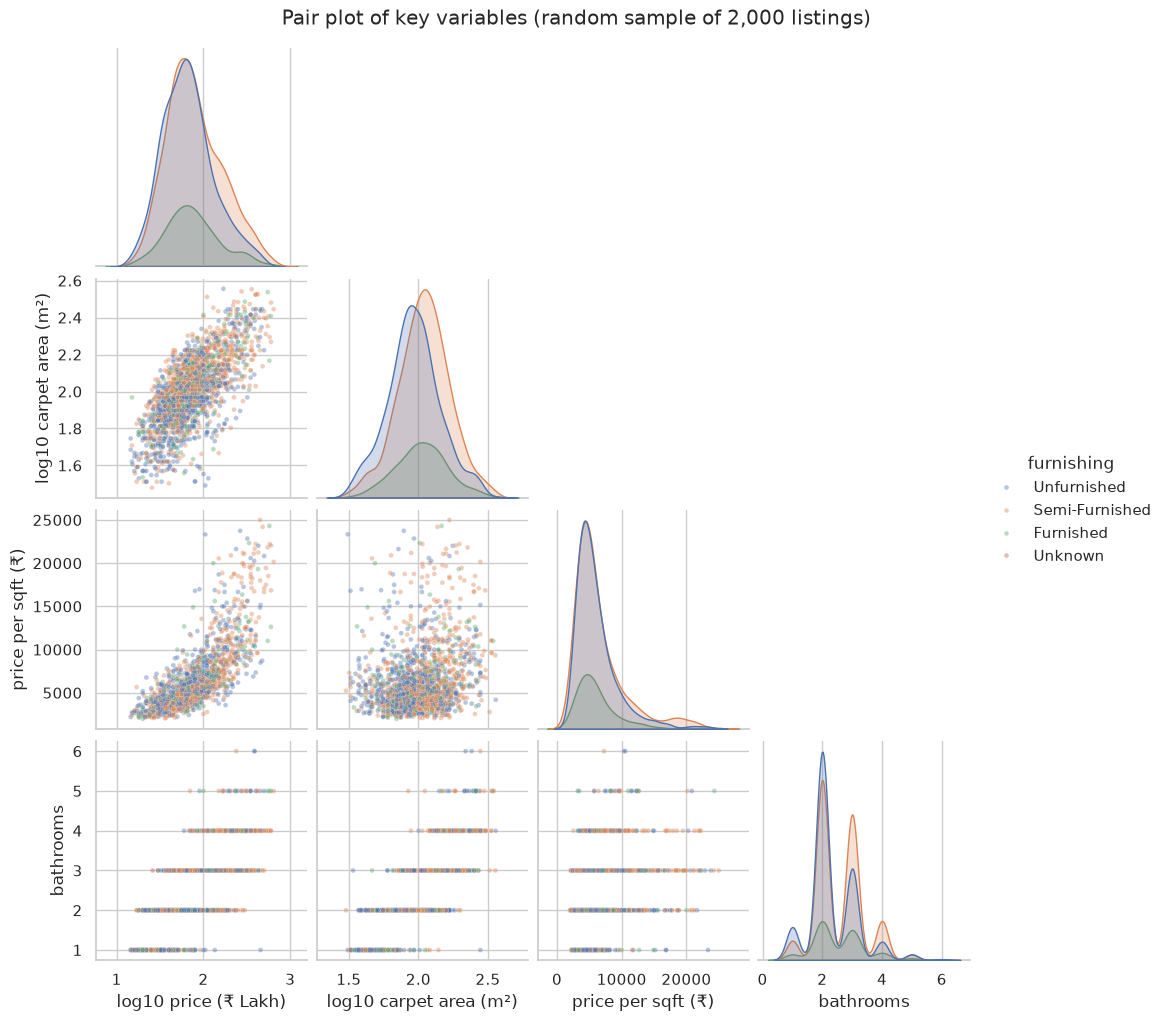

In [71]:
pair_data = df_clean.dropna(subset=["carpet_area_m2"]).sample(2000, random_state=RANDOM_STATE)
pair_data = pd.DataFrame({
    "log10 price (₹ Lakh)": np.log10(pair_data["amount_lakh"]),
    "log10 carpet area (m²)": np.log10(pair_data["carpet_area_m2"]),
    "price per sqft (₹)": pair_data["price_per_sqft"],
    "bathrooms": pair_data["bathroom"].astype(float),
    "furnishing": pair_data["furnishing"],
})

# corner=True draws only the lower half (the upper half would be a mirror image)
grid = sns.pairplot(pair_data, hue="furnishing", corner=True, plot_kws={"alpha": 0.4, "s": 12})
grid.figure.suptitle("Pair plot of key variables (random sample of 2,000 listings)", y=1.02)
plt.show()

**Faceting:** draw the *same* plot once per group, in a grid. `sns.catplot()` does this with the `col=` argument.

**Question: does the price of each typology behave the same in different cities?**

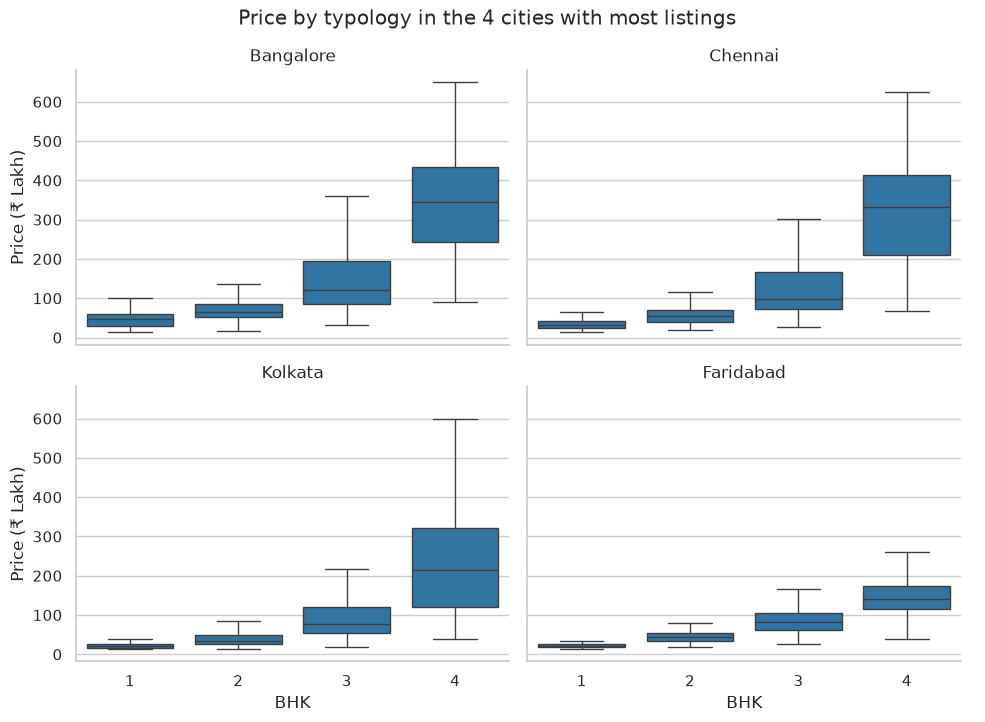

In [72]:
top4_cities = df_clean["location"].value_counts().head(4).index
facet_data = df_clean[df_clean["location"].isin(top4_cities) & df_clean["bhk"].between(1, 4)]

grid = sns.catplot(
    data=facet_data, x="bhk", y="amount_lakh",
    col="location", col_wrap=2,         # one small plot per city, 2 per row
    kind="box", showfliers=False,
    height=3.5, aspect=1.4, color="tab:blue",
)
grid.set_axis_labels("BHK", "Price (₹ Lakh)")
grid.set_titles("{col_name}")           # use only the city name as title
grid.figure.suptitle("Price by typology in the 4 cities with most listings", y=1.03)
plt.show()

In every city, price grows with the number of bedrooms, but **how fast** it grows depends on the city. A model that only knows `bhk` and ignores the city would make big errors.

---
### Your turn: EDA

1. **Furnished cities.** Which city (with at least 500 listings) has the highest share of *Furnished* flats? Hint: `groupby("location")["furnishing"]` and `value_counts(normalize=True)`, or a `crosstab`.
2. **Bathrooms.** Plot the relative price per sqft against the number of bathrooms (1 to 6) with a boxplot. Is there a pattern? Should we compare listings with the same `bhk` only?
3. **Your own design hypothesis.** Write down one hypothesis about the built environment that this dataset can test (e.g. *"new flats are larger than resale flats of the same typology"* or *"flats with more balconies are more expensive per sqft"*). Make **one** plot that tests it, give it a clear title and axis labels, save it with `save_fig()`, and write 2–3 sentences with your conclusion and its limitations.

In [73]:
# 1. Furnished cities

In [74]:
# 2. Bathrooms

In [75]:
# 3. Your own design hypothesis

# 3. Conclusions and next steps

### Key findings
- **Data quality is the first finding.** 64% of the raw rows were duplicates, 2 columns were empty, most numbers were stored as text with mixed units. After cleaning: **~62,500 unique listings** in 81 cities, 24 tidy columns.
- **Prices are strongly right-skewed** (median ₹65 Lakh, mean ₹92 Lakh). On a log scale they are roughly bell-shaped, so we will model the **log of the price**.
- **Typology:** the market is mostly **2 BHK (39%) and 3 BHK (44%)** flats, and ~3 in 4 listings are resales.
- **Size drives the price** (Spearman ≈ 0.7–0.8 with carpet/super area, BHK and bathrooms), but **location drives the price per sqft**: a sqft in New Delhi (median ~₹10,500) costs almost **3×** one in Jaipur (~₹3,800).
- **Design variables, compared within each city:**
  - **Orientation:** South and South-West-facing flats are ~7% above their city median; East and North, the most common orientations, are only ~2% above.
  - **Views:** listings mentioning a **pool** view are ~8% above the city median, a garden/park view ~4%: likely a proxy for gated complexes with amenities.
  - **Floor level:** no clear height premium; ground and top floors are slightly cheaper (−2/−3%).
  - **Efficiency:** the net-to-gross ratio has a median of 0.81 and **falls with building height** (~0.86 up to 4 floors → ~0.74 above 20 floors).
- **Missing information is informative:** listings with "Unknown" orientation, furnishing or transaction are consistently cheaper than the rest.

### 🤔 Limitations
- **Asking prices**, not transaction prices: they reflect what sellers *hope* to get.
- **Sampling bias**: roughly the same number of listings per city, whatever the size of the city. Good for comparing cities, not for describing the whole Indian market (and even less other countries).
- **Self-reported data**: sellers choose what to fill in. Missing orientation or views may not be random.
- **Cleaning decisions shape results**: other thresholds for outliers or other ways of filling missing values would give (slightly) different numbers. That is why we documented every decision.

### "Ready for modelling" checklist (for Day 2)
- [x] **Target defined**: `amount` (asking price, ₹), probably on a **log scale**
- [x] **No duplicates**
- [x] **Numeric columns are numeric**, with **consistent units** (sqft / m², ₹)
- [x] **Missing values** handled, and every decision documented (imputers will be re-fitted on the training set only)
- [x] **Outliers** removed with a documented rule (1st–99th percentile)
- [x] **Leakage columns flagged**: `price_per_sqft` and `relative_price` are derived from the price → **must not be used as model inputs**
- [ ] Categorical columns still need to be **encoded** as numbers → Day 2

The clean dataset is saved in `data/house_prices_clean.csv`, ready to be loaded on Day 2.

### From notebook to deliverable
Every class exercise in this course is submitted as a **structured GitHub repository**. Use this notebook as a model:

```
my-day1-assignment/
├── README.md            # use case, dataset card (source + licence), how to run, main figures
├── requirements.txt     # pandas, numpy, matplotlib, seaborn, scikit-learn, kagglehub ...
├── .gitignore           # ignore large raw data, .venv, checkpoints ...
├── data/                # small/clean data only (raw data is downloaded by the notebook)
├── notebooks/
│   └── data_cleaning_and_EDA.ipynb
└── figures/             # the PNGs exported with save_fig()
```

Checklist before you submit:
- [ ] The notebook **runs from top to bottom** without errors (*Restart kernel → Run all*)
- [ ] Every step has **markdown explaining what and why**
- [ ] The **dataset source** and **use case** are described
- [ ] **Figures** have titles, axis labels and units, and are exported to `figures/`
- [ ] No **absolute paths** and no **API keys** in the code

### References
- [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html), especially *Working with missing data* and *Group by*
- [seaborn tutorial and example gallery](https://seaborn.pydata.org/tutorial.html)
- [matplotlib "Anatomy of a figure"](https://matplotlib.org/stable/gallery/showcase/anatomy.html)
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.), O'Reilly. Chapter 2: *End-to-End Machine Learning Project* (a housing dataset, too!)
- [Kaggle Learn: Data Cleaning](https://www.kaggle.com/learn/data-cleaning)